<p class="lead">Every unit before this one taught a technique. This one teaches the thing the techniques are for: a finished piece of research that somebody else can check. It is meant to be read twice — at the beginning of your thesis, to see what will be expected and in what order, and at the end, as the audit checklist you run before handing anything in. It contains the laboratory's three project tracks with a specification for each, the analysis plan you write <em>before</em> fitting a single model, a complete worked miniature of a QSAR project executed end to end on the frozen ROCK1 data, the rubric expanded into criteria a supervisor can tick, the deliverables and a realistic timeline. The miniature is deliberately small: its purpose is not to be a good model but to show the whole arc of a defensible project in one place, including the two points where it would have been easy to lie.</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad cierra el curso con el proyecto final. Define las tres vías del laboratorio — QSAR y cribado virtual basado en ligandos, análisis de simulaciones y datos biomédicos — cada una con su especificación de datos, validación y entregables, e introduce el plan de análisis escrito <em>antes</em> de modelar junto con los tres puntos de control con el supervisor. A continuación ejecuta una miniatura completa de la vía 1 sobre los datos congelados de ROCK1: procedencia verificada con SHA-256, curación reutilizada, partición por andamiaje decidida de antemano, líneas base, un modelo ajustado, el error con intervalo bootstrap, dos modos de fallo exhibidos, dominio de aplicabilidad, lista priorizada, figura de publicación, párrafo de Métodos y ficha del modelo. Termina con la rúbrica detallada, una auditoría ejecutable y el calendario de entregas.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Carry a project from question to repository: data acquisition with provenance, documented curation, exploratory analysis, baseline and tuned models or analyses, honest validation, uncertainty, interpretation, publication figures, a Methods section, tested code and a DOI.</li>
<li>Write a pre-registration-style analysis plan before modelling, and recognise which later decisions the plan forbids you to make.</li>
<li>Specify your own project inside one of the three tracks, with its data, its unit of prediction, its validation design and its deliverable claim.</li>
<li>Defend every number in your report against the checklists of Blocks C–F of this course, and read each one against the noise floor of the data.</li>
<li>Score a submission with the laboratory's rubric, and run the audit checklist on your own work before anybody else does.</li>
<li>Present the work in a ten-minute lab-meeting talk built from the figures the project produced.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read Sections 1–3 before starting your project and Sections 5–7 before submitting it; run Section 4 once, line by line. In Google Colab run <code>!pip install rdkit</code> before the setup cell; NumPy, pandas, matplotlib, scikit-learn and SciPy are already installed. Nothing here is new machinery — every method in the miniature was taught in an earlier unit and is cited back to it.</p></div>

In [1]:
# Setup. In Google Colab run once:  !pip install rdkit
from pathlib import Path
import urllib.request, json, hashlib, textwrap, tempfile, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, rdkit, scipy
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog("rdApp.*")
np.random.seed(0)
RNG = np.random.default_rng(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"
def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest
def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| rdkit", rdkit.__version__)

numpy 2.4.6 | pandas 3.0.3 | scipy 1.17.1 | scikit-learn 1.9.0 | rdkit 2026.03.4


The versions printed above are part of the result. A capstone that reports a number without the version of the library that produced it is asking its reader to take the number on trust, and the reproducibility literature of the last decade is a long argument against doing that<sup class="c"><a href="#r1">[1]</a></sup><sup class="c"><a href="#r6">[6]</a></sup>.

## 1. The capstone is the project, not the notebook

A capstone is not a bigger exercise. The exercises in Units 1–26 each isolated one decision; a project is the same decisions taken together, under time pressure, with nobody saying which one matters. What changes is the unit of judgement: an examiner does not grade a cell, they grade a **claim** — "this model predicts ROCK1 potency for new chemotypes to within about 0.8 log units", "conformation B is populated 12 % more at 340 K than at 300 K", "these 30 genes separate diseased from healthy tissue in an independent cohort". Everything here exists to make a claim of that shape survive a sceptical reader.

Two findings from the wider literature set the standard. The first is that most computational results are not reproducible by default: in Nature's survey of 1,576 researchers, more than 70 % had failed to reproduce another scientist's experiment and more than half had failed to reproduce their own<sup class="c"><a href="#r7">[7]</a></sup>, and the diagnosis is almost always that the data, the exact code or the environment were never captured<sup class="c"><a href="#r6">[6]</a></sup><sup class="c"><a href="#r35">[35]</a></sup>. The second is that in machine-learning-based science the dominant error is not a bug but a **leak**: Kapoor and Narayanan found data leakage in 294 papers across 17 fields, each reporting performance that evaporated once the leak was closed<sup class="c"><a href="#r8">[8]</a></sup>. The remedy for both is procedural: fix the data, write the plan, choose the validation design before you see the scores, and publish everything somebody else would need to repeat the work<sup class="c"><a href="#r1">[1]</a></sup><sup class="c"><a href="#r2">[2]</a></sup><sup class="c"><a href="#r3">[3]</a></sup>.

<div class="box bridge"><h4>Domain context — what the laboratory's projects actually look like</h4>
<p>The Laboratorio de Bioinformática y Química Computacional works on a small number of protein targets — kinases such as ROCK1, receptors such as P2X3 and the apelin receptor, protein–protein interfaces such as MDM2/MDM4, bacterial efflux pumps — and on biomedical datasets from collaborating clinical groups. A thesis in the group has one of three shapes. <strong>Ligand-based work</strong> starts from a table of measured activities: each row is a molecule, the column of interest is a potency such as an IC<sub>50</sub> (the concentration that halves a biological response) or a K<sub>i</sub> (a binding constant), and the goal is a model that ranks untested molecules. <strong>Simulation work</strong> starts from molecular-dynamics trajectories: a physics engine integrates the motion of a protein and its water, and what reaches the data scientist is a set of time series — distances, angles, root-mean-square deviations — from several independent repetitions called replicas. <strong>Biomedical work</strong> starts from a matrix of measurements on patients or samples, typically gene-expression values from a public repository, with samples in columns and genes in rows. The three kinds of data are utterly different; the project discipline around them is identical, which is why one capstone unit serves all three.</p></div>

The three tracks below are three instances of one pipeline, drawn in Figure 1: a spine of eleven stages every project walks, with the track-specific content of four of them underneath.

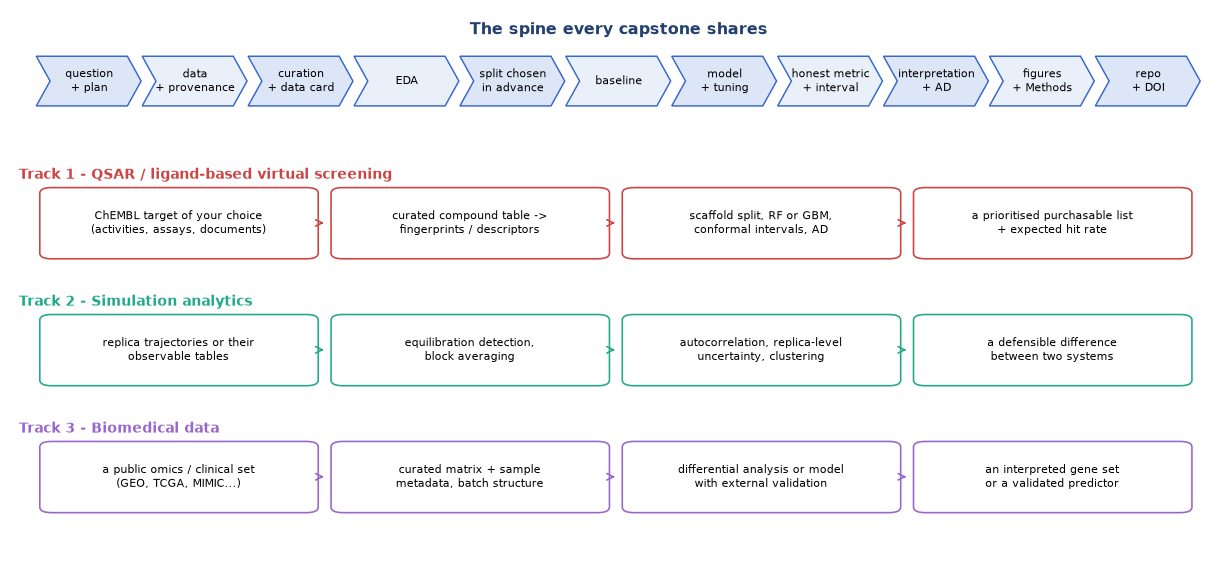

In [2]:
# Figure 1: the shared spine of a capstone and the three tracks that instantiate it.
from matplotlib.patches import FancyBboxPatch, Polygon
stage_names = ["question\n+ plan", "data\n+ provenance", "curation\n+ data card", "EDA", "split chosen\nin advance",
               "baseline", "model\n+ tuning", "honest metric\n+ interval", "interpretation\n+ AD",
               "figures\n+ Methods", "repo\n+ DOI"]
fig, ax = plt.subplots(figsize=(9.5, 4.6))
w = 10 / len(stage_names)
for i, s in enumerate(stage_names):
    x = i * w
    ax.add_patch(Polygon([[x, 8.3], [x + w * 0.86, 8.3], [x + w * 0.99, 8.75], [x + w * 0.86, 9.2],
                          [x, 9.2], [x + w * 0.13, 8.75]], closed=True,
                         fc="#dce6f6" if i % 2 == 0 else "#eaf0fa", ec="#36c", lw=0.8))
    ax.text(x + w * 0.5, 8.75, s, ha="center", va="center", fontsize=6.3)
ax.text(5, 9.6, "The spine every capstone shares", ha="center", fontsize=9, fontweight="bold", color="#24406e")
lanes = [("Track 1 - QSAR / ligand-based virtual screening", "#c44",
          ["ChEMBL target of your choice\n(activities, assays, documents)",
           "curated compound table ->\nfingerprints / descriptors",
           "scaffold split, RF or GBM,\nconformal intervals, AD",
           "a prioritised purchasable list\n+ expected hit rate"]),
         ("Track 2 - Simulation analytics", "#2a8",
          ["replica trajectories or their\nobservable tables",
           "equilibration detection,\nblock averaging",
           "autocorrelation, replica-level\nuncertainty, clustering",
           "a defensible difference\nbetween two systems"]),
         ("Track 3 - Biomedical data", "#96c",
          ["a public omics / clinical set\n(GEO, TCGA, MIMIC...)",
           "curated matrix + sample\nmetadata, batch structure",
           "differential analysis or model\nwith external validation",
           "an interpreted gene set\nor a validated predictor"])]
for j, (name, col, boxes) in enumerate(lanes):
    yl = 6.6 - j * 2.3
    ax.text(-0.15, yl + 0.45, name, ha="left", va="center", fontsize=7.6, fontweight="bold", color=col)
    for k, b in enumerate(boxes):
        x = k * 2.5 + 0.05
        ax.add_patch(FancyBboxPatch((x, yl - 1.05), 2.35, 1.25,
                                    boxstyle="round,pad=0.02,rounding_size=0.1", fc="white", ec=col, lw=0.9))
        ax.text(x + 1.17, yl - 0.42, b, ha="center", va="center", fontsize=6.1)
        if k < 3:
            ax.annotate("", xy=(x + 2.45, yl - 0.42), xytext=(x + 2.36, yl - 0.42),
                        arrowprops=dict(arrowstyle="->", color=col, lw=0.9))
ax.set_xlim(-0.2, 10.1); ax.set_ylim(-0.2, 10); ax.axis("off")
fig.tight_layout()

<p class="caption"><b>Figure 1.</b> The capstone pipeline. The eleven chevrons are the stages every project passes through in order; the three lanes show what four of those stages contain in each track. Nothing in the spine is optional: provenance before data, a data card before analysis, a split chosen before fitting, an interval on every metric, a repository with a DOI at the end. The arrows are one-way on purpose — changing the split after seeing a score invalidates the rest of the diagram.</p>

## 2. The three tracks

Each track is a specification you can hand to a supervisor; the rows are the same in all three because the rubric is. Choose one and stay in it — a project that tries two has half a validation design for each.

### 2.1 Track 1 — QSAR and ligand-based virtual screening

**The question.** "Can we rank untested molecules for target X well enough to choose which fifty to buy or synthesise?" Target X is yours to choose: a ChEMBL target with at least a few hundred measured compounds that the group has a reason to care about.

| element | specification |
|---|---|
| raw data | all `IC50`/`Ki`/`Kd` activities for the target from the ChEMBL API<sup class="c"><a href="#r27">[27]</a></sup>, downloaded once, frozen, hashed, with query and release recorded |
| curation | the Unit 6 protocol: standardisation, unit harmonisation, censored records flagged, replicate aggregation per parent, a per-step exclusion log |
| unit of prediction | one standardised compound, not one measurement |
| target variable | pActivity = −log<sub>10</sub>(activity in M), median over exact measurements |
| features | Morgan fingerprints (radius 2, 2,048 bits)<sup class="c"><a href="#r22">[22]</a></sup> and/or descriptors, computed inside the pipeline |
| validation | a Bemis–Murcko scaffold<sup class="c"><a href="#r21">[21]</a></sup> or leave-cluster-out split as the headline; a random split only as a contrast<sup class="c"><a href="#r17">[17]</a></sup><sup class="c"><a href="#r18">[18]</a></sup> |
| primary metric | RMSE in log units with a bootstrap 95 % interval; Spearman ρ as a ranking check |
| uncertainty & domain | nearest-neighbour similarity or conformal intervals; an explicit domain rule<sup class="c"><a href="#r25">[25]</a></sup><sup class="c"><a href="#r26">[26]</a></sup> |
| deliverable claim | N prioritised candidates from a purchasable library, each with a prediction, an interval and an in-domain flag, plus the expected hit rate |

**What makes it fail.** A random split quoted as if it answered the new-chemotype question; duplicate structures on both sides of the split; censored values (`>10 µM`) treated as exact; a prioritised list entirely outside the applicability domain. Sections 4.3, 4.7 and 4.8 exhibit three of these four.

### 2.2 Track 2 — Simulation analytics

**The question.** "Do two systems — two temperatures, a wild type and a mutant, an apo and a holo form — differ in a property we can measure from the trajectories, by more than the sampling error of our own simulations?"

| element | specification |
|---|---|
| raw data | replica trajectories, or the course's frozen observable tables (`md_trpcage_observables.csv`: two conditions × three replicas × 500 frames), with the protocol recorded |
| curation | equilibration detection and discard, frame rate and units documented, a per-replica quality table<sup class="c"><a href="#r30">[30]</a></sup> |
| unit of prediction | one **replica**, never one frame — successive frames are not independent |
| target variable | the observable the question is about (helix fraction, a distance, a contact count) |
| features | time series and their summaries; principal components of the coordinates for clustering |
| validation | between-replica variance as the error bar; block averaging and autocorrelation times<sup class="c"><a href="#r30">[30]</a></sup> |
| primary metric | the between-condition difference with an interval computed across replicas, plus an effect size |
| uncertainty & domain | what the simulation length can and cannot resolve; a convergence plot per claim |
| deliverable claim | "property P differs by Δ (95 % CI …), n = 3 replicas per condition", or an honest "our sampling cannot resolve a difference of this size" |

**What makes it fail.** Treating 500 correlated frames as 500 observations, which shrinks every interval by an order of magnitude; one replica per condition; a clustering never shown to be stable under reseeding; a disagreeing replica quietly discarded. The LiveCoMS article on sampling quality is this track's checklist<sup class="c"><a href="#r30">[30]</a></sup>.

### 2.3 Track 3 — Biomedical data

**The question.** "Which features separate the two clinical groups, and does that separation hold in a cohort we did not use to find it?"

| element | specification |
|---|---|
| raw data | a public omics or clinical dataset (the course ships `geo_periodontitis_expr.csv`: 5,000 genes × 138 samples, 69 within-patient pairs) with accession, platform and processing recorded |
| curation | metadata reconciled with the matrix, duplicated patients identified, batch structure described, a sample-exclusion log |
| unit of prediction | one **patient**, not one sample — paired samples from a patient are not independent |
| target variable | disease status, or a continuous clinical score |
| features | genes, proteins or clinical variables; all filtering done inside the folds |
| validation | patient-grouped cross-validation plus external validation whenever a second cohort exists<sup class="c"><a href="#r13">[13]</a></sup>; FDR control for differential tests<sup class="c"><a href="#r33">[33]</a></sup> |
| primary metric | AUC with an interval, or the number of differential genes at a stated FDR, with effect sizes |
| uncertainty & domain | calibration; the population the model applies to; a sample-size justification<sup class="c"><a href="#r14">[14]</a></sup> |
| deliverable claim | "a k-gene signature separates diseased from healthy tissue with AUC … in an independent cohort", with its enrichment or network interpretation<sup class="c"><a href="#r31">[31]</a></sup><sup class="c"><a href="#r32">[32]</a></sup> |

**What makes it fail.** Feature selection on the whole matrix before splitting — the classic leak<sup class="c"><a href="#r8">[8]</a></sup>; two samples from one patient split across train and test; a p-value list without FDR control; a claim about patients supported by an analysis of samples. TRIPOD+AI is the standard your Methods must satisfy<sup class="c"><a href="#r13">[13]</a></sup>.

<div class="exercise"><h4>Exercise 1</h4>
<p>Write the table of your own project — the same eleven rows — before you read Section 4. Be specific: name the target or the dataset, the unit of prediction, the split, the metric and the sentence you intend to be able to write at the end. If you cannot fill the "deliverable claim" row, you do not yet have a project; you have a dataset.</p></div>

## 3. The analysis plan, written before the modelling

The plan is a short document, shown to your supervisor **before any model is fitted**, that commits you to the decisions a later you would be tempted to make after seeing the scores. It is a lightweight pre-registration, adopted for the same reason: a study whose analysis is specified in advance cannot silently become a different study once the results are in<sup class="c"><a href="#r9">[9]</a></sup>. The failure it prevents has a name in the methodological literature — researcher degrees of freedom, the many small, individually defensible choices whose total is a result that is not real<sup class="c"><a href="#r10">[10]</a></sup> — and a measured consequence in computational methods research, where tuning the protocol on the evaluation data is the main engine of over-optimistic reporting<sup class="c"><a href="#r11">[11]</a></sup>.

### 3.1 The template

Fill in these nine fields. Half a page is enough; two pages means you are designing the paper rather than the analysis.

1. **Question.** One sentence — "does / how well does / which …" — answerable with the data you have already frozen.
2. **Target variable and its units**, including the transformation (log, z-score) and why.
3. **Unit of prediction.** The row of your final table: a compound, a replica, a patient. Grouping and leakage both follow from this line.
4. **Data and its provenance.** Source, version or accession, download date, licence, hash, and what you will exclude with what rule.
5. **Split strategy, chosen now.** Which split, which grouping variable, what future it simulates, and which sensitivity analyses will be reported as contrasts.
6. **Primary metric and baselines.** One metric with its interval, the baselines it must beat (always including a trivial one), and the noise floor if you can estimate it.
7. **Decision rule.** What result would make you say the model works — and what result would make you say it does not. The second clause is what makes the first meaningful.
8. **Planned figures.** Three to six, by name; anything added later needs a reason.
9. **Deviations.** A log, appended during the project, of every departure from the plan with its justification.

The plan is a file in the repository, not an email. Written as structured text it becomes checkable, as the cell below shows for the miniature of Section 4 — which lets the notebook assert that what it did matches what it said it would do.

In [3]:
# The analysis plan of the worked miniature, written before any model is fitted.
PLAN = {
    "question": "How well does a fingerprint model predict ROCK1 potency for chemotypes it has not seen?",
    "target": "pActivity = -log10(activity in M), median over exact measurements",
    "unit_of_prediction": "one standardised compound (InChIKey), not one measurement",
    "data": {"file": "rock1_chembl_curated.csv", "source": "ChEMBL_37 via the EBI REST API",
             "exclusions": "censored-only compounds (relation > or <) removed from the regression set"},
    "split": {"primary": "Bemis-Murcko scaffold split, 80/20, largest families to training",
              "simulates": "prediction for chemotypes absent from the training data",
              "sensitivity": "the same pipeline under a random split, reported as a contrast only"},
    "primary_metric": "RMSE in log units on the scaffold hold-out, with a 95% bootstrap interval",
    "baselines": ["mean predictor (DummyRegressor)", "ridge on fingerprints",
                  "untuned random forest", "noise floor sigma ~ 0.51 log units (Unit 6)"],
    "decision_rule": ("the model is useful if its hold-out RMSE interval lies entirely below the mean predictor "
                      "AND the top-20 prioritised list is enriched in measured actives; it is NOT useful if the "
                      "interval overlaps the mean predictor or if the candidates fall outside the domain"),
    "planned_figures": ["split diagnostic", "tuning curve", "metric with interval",
                        "error vs distance to training", "predicted vs observed (publication figure)"],
    "deviations": [],
}
print(json.dumps(PLAN, indent=1)[:1200], "...")
print("\nfields:", len(PLAN), "| planned figures:", len(PLAN["planned_figures"]),
      "| baselines:", len(PLAN["baselines"]))

{
 "question": "How well does a fingerprint model predict ROCK1 potency for chemotypes it has not seen?",
 "target": "pActivity = -log10(activity in M), median over exact measurements",
 "unit_of_prediction": "one standardised compound (InChIKey), not one measurement",
 "data": {
  "file": "rock1_chembl_curated.csv",
  "source": "ChEMBL_37 via the EBI REST API",
  "exclusions": "censored-only compounds (relation > or <) removed from the regression set"
 },
 "split": {
  "primary": "Bemis-Murcko scaffold split, 80/20, largest families to training",
  "simulates": "prediction for chemotypes absent from the training data",
  "sensitivity": "the same pipeline under a random split, reported as a contrast only"
 },
 "primary_metric": "RMSE in log units on the scaffold hold-out, with a 95% bootstrap interval",
 "baselines": [
  "mean predictor (DummyRegressor)",
  "ridge on fingerprints",
  "untuned random forest",
  "noise floor sigma ~ 0.51 log units (Unit 6)"
 ],
 "decision_rule": "the mod

The printed plan has nine fields and names five figures and four baselines before a single row of data has been read. Two of its clauses do real work later. The `split.primary` clause means that when Section 4.7 computes a prettier number under a random split, that number cannot become the headline — the plan already assigned it the role of a contrast. The `decision_rule` clause contains its own refutation, so Section 4.6 cannot quietly redefine success after seeing the interval.

### 3.2 The three supervisor checkpoints

Three short meetings, each with one artefact, because the three mistakes that cost a thesis a semester are all made early and are all cheap to catch.

| checkpoint | when | artefact you bring | what the supervisor checks |
|---|---|---|---|
| **C1 — data card** | week 4 | one page: source, version, hash, counts, exclusion log, known defects, licence | that the data are frozen, the exclusions are rules, and the unit of prediction is correct |
| **C2 — validation plan** | week 8 | the plan, the split code with its diagnostic figure, the baselines already run | that the split matches the claim, a trivial baseline exists, and nothing has been tuned on the hold-out |
| **C3 — figure draft** | week 16 | the planned figures from real results, with captions written | that each figure answers one question and nothing in it contradicts the Methods |

Figure 2 places these checkpoints on the nine-stage timeline of Section 7. Notice that C2 falls before any tuned model exists: by design, the validation design is approved while it is still cheap to change.

stages: 9 | nominal duration: 18 weeks


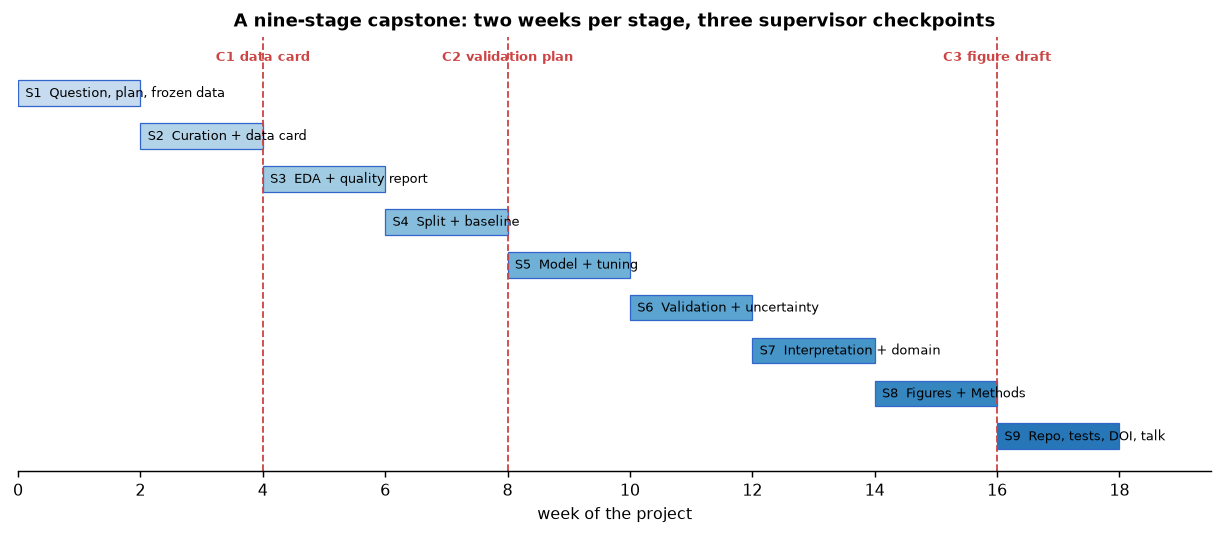

In [4]:
# Figure 2: the nine stages of a capstone and the three supervisor checkpoints.
stages = [("S1  Question, plan, frozen data", 0), ("S2  Curation + data card", 2), ("S3  EDA + quality report", 4),
          ("S4  Split + baseline", 6), ("S5  Model + tuning", 8), ("S6  Validation + uncertainty", 10),
          ("S7  Interpretation + domain", 12), ("S8  Figures + Methods", 14), ("S9  Repo, tests, DOI, talk", 16)]
checkpoints = [(4, "C1 data card"), (8, "C2 validation plan"), (16, "C3 figure draft")]
fig, ax = plt.subplots(figsize=(9.5, 4.2))
for i, (name, start) in enumerate(stages):
    ax.barh(len(stages) - i, 2, left=start, height=0.6, color=plt.cm.Blues(0.25 + 0.06 * i),
            edgecolor="#36c", lw=0.7)
    ax.text(start + 0.12, len(stages) - i, name, va="center", fontsize=7)
for x, lab in checkpoints:
    ax.axvline(x, color="#c44", ls="--", lw=1)
    ax.text(x, len(stages) + 0.75, lab, color="#c44", fontsize=7, ha="center", fontweight="bold")
ax.set_xlim(0, 19.5); ax.set_ylim(0.2, len(stages) + 1.3); ax.set_yticks([])
ax.set_xticks(range(0, 19, 2)); ax.set_xlabel("week of the project")
ax.set_title("A nine-stage capstone: two weeks per stage, three supervisor checkpoints")
ax.spines["left"].set_visible(False)
fig.tight_layout()
print("stages:", len(stages), "| nominal duration:", 2 * len(stages), "weeks")

<p class="caption"><b>Figure 2.</b> The capstone schedule. Nine stages of two weeks, eighteen weeks in total, with the checkpoints in red at weeks 4, 8 and 16. The ordering is the point: the data card is approved before any analysis, the validation plan before any tuned model, the figures before the text explaining them.</p>

<div class="exercise"><h4>Exercise 2</h4>
<p>Take the plan of Exercise 1 and write its three checkpoint artefacts as empty files in your repository now: <code>docs/data_card.md</code>, <code>docs/analysis_plan.md</code> and <code>figures/README.md</code>. Projects that create these files on day one finish them; projects that intend to write them at the end do not.</p></div>

## 4. A worked miniature of Track 1, end to end

The rest of this section executes a complete, deliberately tiny Track 1 project on the frozen ROCK1 snapshot. It runs in about a minute and is not a contribution to the ROCK1 literature: the sibling units hold the depth — Unit 6 the curation protocol, Unit 11 the leakage-free pipeline, Unit 12 the splits and metrics, Unit 14 the ensembles and tuning, Unit 17 the applicability domain, Unit 23 the publication figure. What is new here is the **order**, the **provenance** and the **audit**.

### 4.1 Provenance: the hash comes first

Before anything is analysed, the files are pinned. A hash of each raw file, stored with the query that produced it and the download date, converts "the ChEMBL data" into a specific object comparable byte for byte years later — the minimum content of the F in FAIR<sup class="c"><a href="#r5">[5]</a></sup> and the first line of every reproducibility checklist<sup class="c"><a href="#r1">[1]</a></sup><sup class="c"><a href="#r2">[2]</a></sup>. The cell below recomputes the SHA-256 of the curated table and compares it with the frozen manifest.

In [5]:
# Provenance check: recompute the hash of the data file and compare it with the frozen manifest.
manifest = json.load(open(data_path("manifest_rock1.json"), encoding="utf-8"))
FILE = "rock1_chembl_curated.csv"

def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

digest = sha256_of(data_path(FILE))
expected = manifest["files"][FILE]["sha256"]
HASH_OK = digest == expected
print("file           :", FILE)
print("sha256 (now)   :", digest[:32], "...")
print("sha256 (frozen):", expected[:32], "...")
print("match          :", HASH_OK)
print("source         :", manifest["source"], "|", manifest["chembl_release"],
      "released", manifest["chembl_release_date"], "| downloaded", manifest["download_date"])
print("licence        :", manifest["licence"])
print("query          :", manifest["query"])

file           : rock1_chembl_curated.csv
sha256 (now)   : 765ab0cf633b4dd26a9be200f21c7972 ...
sha256 (frozen): 765ab0cf633b4dd26a9be200f21c7972 ...
match          : True
source         : ChEMBL REST API (EBI) | ChEMBL_37 released 2026-05-01 | downloaded 2026-10-18
licence        : CC BY-SA 3.0 (ChEMBL)
query          : activity.json?target_chembl_id=CHEMBL3231&standard_type__in=IC50,Ki,Kd


The hash matches, so every number below refers to an unambiguously identified file. In your own project this check belongs in a test (Section 4.11), not in a cell you might forget to run: a silent change in an input is the failure mode that makes every downstream number wrong without anything looking broken.

<div class="box bridge"><h4>Domain context — what a ChEMBL activity record is</h4>
<p>ChEMBL is the European public repository of measured bioactivities, extracted by curators from the medicinal-chemistry literature<sup class="c"><a href="#r27">[27]</a></sup>. One record is one measurement of one compound against one target in one assay, from one publication. The pitfalls that make curation necessary are all in the raw file of this course: the same compound measured in twelve assays; three incomparable measurement types (IC<sub>50</sub>, K<sub>i</sub>, K<sub>d</sub>) in one column; <strong>censored</strong> values, where the experiment established only that the activity is weaker than the highest concentration tested (<code>&gt; 10000 nM</code>); units differing by nine orders of magnitude; duplicate deposits of one paper. The curated table aggregates to one row per standardised parent structure and keeps censored compounds flagged rather than deleting them, because excluding them silently biases the potency distribution upwards.</p></div>

### 4.2 Curation reuse and the data card

The capstone does not re-invent curation: it reuses a documented protocol and reports its exclusion log. That log is the body of the data card — ten steps, each with the rows and molecules that survived, so a reader sees how 5,089 raw records became a modelling table.

 step                                                    description  n_rows  n_molecules
    1                     raw records as delivered by the ChEMBL API    5089         4312
    2               drop rows without a structure (canonical_smiles)    5086         4309
    3          human target only (target_organism == 'Homo sapiens')    5086         4309
    4                        drop ChEMBL data_validity_comment flags    5073         4303
    5                     drop rows without a numeric standard_value    5047         4292
    6             harmonise units to nM (drop non-convertible units)    5047         4292
    7            drop non-positive or absurd values (<=0 or >1e8 nM)    5047         4292
    8 RDKit standardisation (normalise, largest fragment, uncharg...    5047         4292
    9          keep small organic molecules (3 <= heavy atoms <= 70)    5045         4290
   10 aggregate replicate measurements per standardised InChIKey ...    4280         4280

curated t

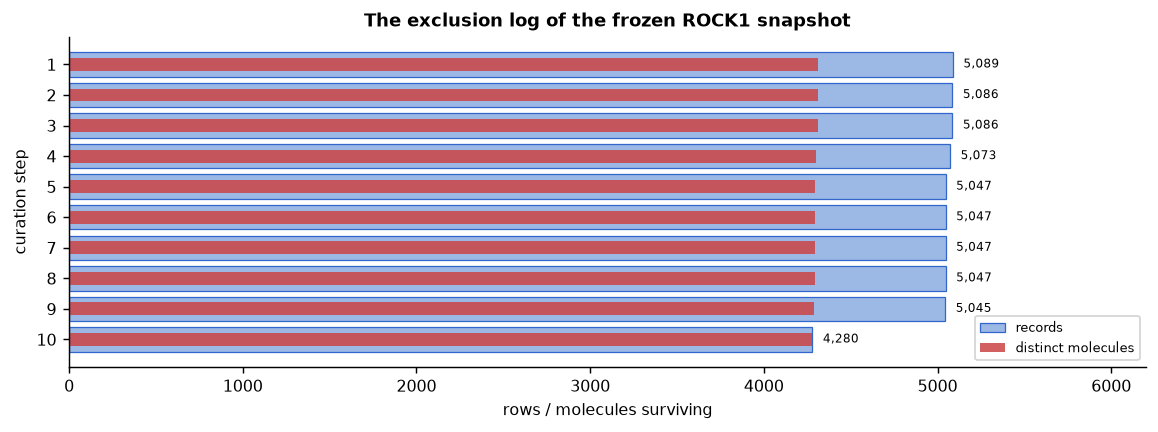

In [6]:
# The curation log is the data card: every exclusion is a rule with a count.
log = load_data("rock1_curation_log.csv")
df = load_data(FILE)
print(log[["step", "description", "n_rows", "n_molecules"]].to_string(index=False, max_colwidth=62))
print("\ncurated table:", df.shape[0], "compounds x", df.shape[1], "columns")
print("censored-only compounds (excluded from the regression target):", int(df["censored"].sum()))
print("compounds with at least one exact measurement:", int((~df["censored"]).sum()))

fig, ax = plt.subplots(figsize=(9.0, 3.4))
ax.barh(log["step"], log["n_rows"], color="#9cb8e4", edgecolor="#36c", lw=0.7, label="records")
ax.barh(log["step"], log["n_molecules"], height=0.42, color="#c44", alpha=0.85, label="distinct molecules")
for s, r, m in zip(log["step"], log["n_rows"], log["n_molecules"]):
    ax.text(r + 60, s, f"{r:,}", va="center", fontsize=6.5)
ax.invert_yaxis(); ax.set_yticks(log["step"]); ax.set_ylabel("curation step")
ax.set_xlabel("rows / molecules surviving"); ax.set_xlim(0, 6200)
ax.legend(fontsize=7, loc="lower right")
ax.set_title("The exclusion log of the frozen ROCK1 snapshot")
fig.tight_layout()

<p class="caption"><b>Figure 3.</b> The curation funnel. Of 5,089 raw activity records, 5,045 survive the ten deterministic steps, and aggregating replicates per standardised structure collapses them to 4,280 compounds — of which 2,764 carry at least one exact measurement and form the regression set. The gap between the blue bar (records) and the red bar (distinct molecules) at every step is the replicate structure that makes compound-level aggregation necessary. No step removes more than 1 % of the rows; a protocol that discards a third of the data would need its own justification in the Methods.</p>

The data card adds three things the log does not contain: the licence (CC BY-SA 3.0), the defects that survive curation (mixed assay types; 60 compounds whose replicates span more than a log unit) and the intended use — ranking untested compounds for this target, not predicting absolute potency elsewhere. That triple is what the "datasheets for datasets" proposal asks for<sup class="c"><a href="#r29">[29]</a></sup>, and it is the artefact of checkpoint C1.

### 4.3 The split, chosen before any model is fitted

The plan committed to a Bemis–Murcko scaffold split<sup class="c"><a href="#r21">[21]</a></sup>: families sorted by size, the largest to training until 80 % of the compounds are used, the rare isolated structures to the hold-out. It simulates the question the laboratory actually asks — can the model say anything about a chemotype it has not seen?<sup class="c"><a href="#r17">[17]</a></sup><sup class="c"><a href="#r18">[18]</a></sup> The random split is computed too, with the role of a contrast assigned in advance.

In [7]:
# Features and the two splits. The scaffold split is the primary design; the random split is a contrast.
from collections import defaultdict
reg = df.loc[~df["censored"]].reset_index(drop=True)
y = reg["pActivity"].to_numpy()
scaffold = reg["scaffold_smiles"].to_numpy()
mols = [Chem.MolFromSmiles(s) for s in reg["std_smiles"]]
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X = np.array([gen.GetFingerprintAsNumPy(m) for m in mols], dtype=np.float32)
fps = [gen.GetFingerprint(m) for m in mols]

def scaffold_split(scaffolds, test_size=0.2):
    '''Deterministic Bemis-Murcko split: largest families to training, the tail to test (Unit 12).'''
    groups = defaultdict(list)
    for i, s in enumerate(scaffolds):
        groups[s].append(i)
    families = sorted(groups.values(), key=lambda g: (-len(g), g[0]))
    n_train = int(round((1 - test_size) * len(scaffolds)))
    train, test = [], []
    for fam in families:
        (train if len(train) < n_train else test).extend(fam)
    return np.array(train), np.array(test)

tr, te = scaffold_split(scaffold, 0.2)
perm = RNG.permutation(len(y)); rtr, rte = perm[:len(tr)], perm[len(tr):]   # contrast only
print("compounds %d | features %d | scaffold families %d" % (len(y), X.shape[1], reg["scaffold_smiles"].nunique()))
print("scaffold split : train %d, test %d, shared scaffolds %d"
      % (len(tr), len(te), len(set(scaffold[tr]) & set(scaffold[te]))))
print("random split   : train %d, test %d, shared scaffolds %d"
      % (len(rtr), len(rte), len(set(scaffold[rtr]) & set(scaffold[rte]))))
print("pActivity  train %.3f +/- %.3f | scaffold test %.3f +/- %.3f | random test %.3f +/- %.3f"
      % (y[tr].mean(), y[tr].std(), y[te].mean(), y[te].std(), y[rte].mean(), y[rte].std()))

compounds 2764 | features 2048 | scaffold families 1218
scaffold split : train 2211, test 553, shared scaffolds 0
random split   : train 2211, test 553, shared scaffolds 191
pActivity  train 6.588 +/- 1.108 | scaffold test 6.187 +/- 1.049 | random test 6.450 +/- 1.092


The two splits differ in two ways that matter. The scaffold split shares **zero** scaffold families between the two sides, while the random split shares several hundred, so most of its hold-out compounds have a near-twin in training. And the scaffold hold-out is less potent than the training set (about 6.19 against 6.59 log units), because potent compounds accumulate in the large optimised series a size-ordered split sends to training — informative rather than broken, but it must be quoted whenever the hold-out numbers are. Figure 4 shows the first difference with the diagnostic of Unit 12: the Tanimoto similarity of every hold-out compound to its nearest training neighbour.

median nearest-neighbour similarity: scaffold 0.661 | random 0.774
scaffold hold-out compounds with similarity below 0.35: 86 (15.6%)


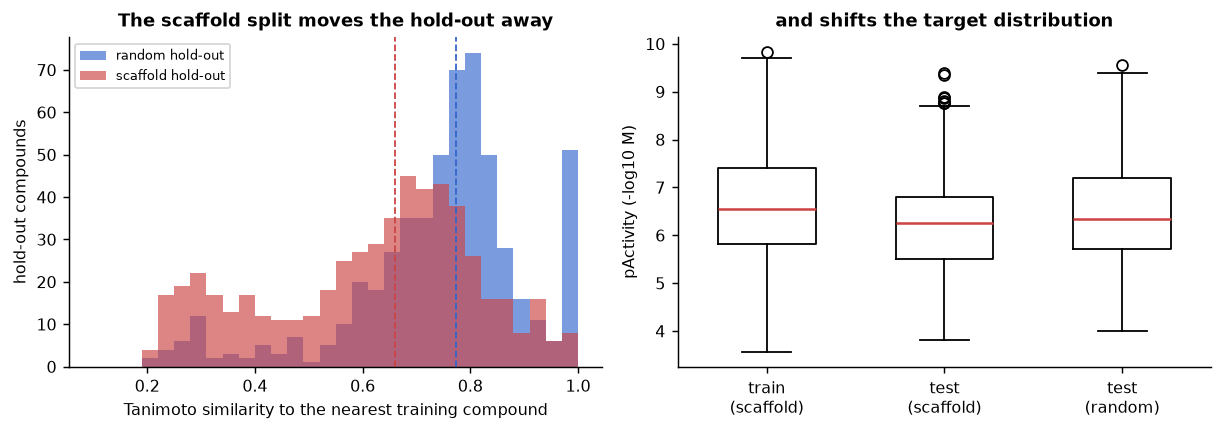

In [8]:
# Figure 4: how far each hold-out compound sits from the training set, and how the target shifts.
fps_tr = [fps[i] for i in tr]
fps_rtr = [fps[i] for i in rtr]
nn_scaf = np.array([max(DataStructs.BulkTanimotoSimilarity(fps[i], fps_tr)) for i in te])
nn_rand = np.array([max(DataStructs.BulkTanimotoSimilarity(fps[i], fps_rtr)) for i in rte])
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
ax = axes[0]
bins = np.linspace(0.1, 1.0, 31)
ax.hist(nn_rand, bins=bins, color="#36c", alpha=0.65, label="random hold-out")
ax.hist(nn_scaf, bins=bins, color="#c44", alpha=0.65, label="scaffold hold-out")
ax.axvline(np.median(nn_rand), color="#36c", ls="--", lw=1)
ax.axvline(np.median(nn_scaf), color="#c44", ls="--", lw=1)
ax.set_xlabel("Tanimoto similarity to the nearest training compound")
ax.set_ylabel("hold-out compounds"); ax.legend(fontsize=7)
ax.set_title("The scaffold split moves the hold-out away")
ax = axes[1]
ax.boxplot([y[tr], y[te], y[rte]], tick_labels=["train\n(scaffold)", "test\n(scaffold)", "test\n(random)"],
           widths=0.55, medianprops=dict(color="#c44", lw=1.4))
ax.set_ylabel("pActivity (-log10 M)")
ax.set_title("and shifts the target distribution")
fig.tight_layout()
print("median nearest-neighbour similarity: scaffold %.3f | random %.3f"
      % (np.median(nn_scaf), np.median(nn_rand)))
print("scaffold hold-out compounds with similarity below 0.35: %d (%.1f%%)"
      % ((nn_scaf < 0.35).sum(), 100 * (nn_scaf < 0.35).mean()))

<p class="caption"><b>Figure 4.</b> Left: the distance from each hold-out compound to the training set. Under the random split the median nearest-neighbour Tanimoto similarity is about 0.78 — most test compounds have a close analogue in training. Under the scaffold split it falls to about 0.66, and roughly 16 % of the hold-out sits below 0.35, where fingerprint models stop interpolating. Right: the scaffold hold-out is also about 0.4 log units less potent than training, while the random hold-out is not.</p>

### 4.4 Baselines

A result without a baseline is not a result. The plan named four: a mean predictor, a linear model on the same features, an untuned random forest, and the noise floor of the data itself. The last is the most important and the most often omitted — Unit 6 estimated this dataset's experimental reproducibility from its replicate measurements at about σ ≈ 0.51 log units, capping the attainable R² near 0.79 for the whole dataset and slightly lower on this hold-out, whose spread is narrower, as the cell below prints. RMSE 0.8 against a noise floor of 0.5 is not a disappointing model but one within a factor of two of the measurement, and saying so is part of honest reporting<sup class="c"><a href="#r19">[19]</a></sup><sup class="c"><a href="#r20">[20]</a></sup>.

In [9]:
# Baselines on the scaffold hold-out, in increasing order of effort.
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from scipy.stats import spearmanr

def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

NOISE_FLOOR = 0.51          # log units, estimated from replicate measurements in Unit 6
baselines = {}
for name, model in [("mean predictor", DummyRegressor(strategy="mean")),
                    ("ridge on fingerprints", Ridge(alpha=10.0)),
                    ("random forest (untuned)", RandomForestRegressor(n_estimators=500, random_state=0, n_jobs=-1))]:
    model.fit(X[tr], y[tr])
    pred = model.predict(X[te])
    baselines[name] = dict(rmse=rmse(y[te], pred), mae=float(mean_absolute_error(y[te], pred)),
                           r2=float(r2_score(y[te], pred)))
    if name == "random forest (untuned)":
        pred_default = pred
base_tab = pd.DataFrame(baselines).T
print(base_tab.round(3).to_string())
print("\nnoise floor (Unit 6): sigma = %.2f log units -> R2 ceiling on this hold-out = %.2f"
      % (NOISE_FLOOR, 1 - NOISE_FLOOR ** 2 / y[te].var()))

                          rmse    mae     r2
mean predictor           1.123  0.906 -0.146
ridge on fingerprints    0.883  0.694  0.292
random forest (untuned)  0.841  0.643  0.358

noise floor (Unit 6): sigma = 0.51 log units -> R2 ceiling on this hold-out = 0.76


The mean predictor scores RMSE 1.12 log units, the ridge model 0.88 and the untuned forest 0.84. Two readings follow. Fingerprints carry real signal — the forest removes about a quarter of the trivial predictor's error. And the gap between the forest and the noise floor, 0.84 against 0.51, says that roughly half the variance a perfect model could explain here is still unexplained, which is what a medicinal chemist needs to hear. For comparison, Unit 11 reported 0.918 for a random-split cross-validated forest on the same data and Unit 14 reported 0.879 under scaffold cross-validation, so this hold-out number is in the expected family.

### 4.5 One tuned model, tuned inside the training set

Tuning happens on the training data only, with a grouped cross-validation respecting the same scaffold structure as the outer split — otherwise the hyperparameter choice is informed by the chemotypes it will be tested on, the mildest and commonest leakage<sup class="c"><a href="#r8">[8]</a></sup>. The grid is deliberately nine random-forest configurations<sup class="c"><a href="#r23">[23]</a></sup>: a small grid is defensible for a capstone, and its size belongs in the Methods.

In [10]:
# A nine-point grid, scored by 5-fold GroupKFold on the TRAINING set only, grouped by scaffold.
from sklearn.model_selection import GroupKFold
gkf = GroupKFold(n_splits=5)
grid = [{"max_features": mf, "min_samples_leaf": ml} for mf in ["sqrt", 0.1, 0.3] for ml in [1, 2, 5]]
rows = []
for cfg in grid:
    fold_scores = []
    for a, b in gkf.split(X[tr], y[tr], groups=scaffold[tr]):
        m = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1, **cfg).fit(X[tr][a], y[tr][a])
        fold_scores.append(rmse(y[tr][b], m.predict(X[tr][b])))
    rows.append({"max_features": str(cfg["max_features"]), "min_samples_leaf": cfg["min_samples_leaf"],
                 "cv_rmse": float(np.mean(fold_scores)), "cv_sd": float(np.std(fold_scores))})
tuning = pd.DataFrame(rows).sort_values("cv_rmse").reset_index(drop=True)
best = tuning.iloc[0]
print(tuning.round(3).to_string(index=False))
print("\nbest configuration: max_features=%s, min_samples_leaf=%d (inner CV RMSE %.3f +/- %.3f)"
      % (best["max_features"], best["min_samples_leaf"], best["cv_rmse"], best["cv_sd"]))
print("spread across the whole grid: %.3f log units" % (tuning["cv_rmse"].max() - tuning["cv_rmse"].min()))

max_features  min_samples_leaf  cv_rmse  cv_sd
        sqrt                 1    0.813  0.031
         0.1                 1    0.814  0.025
         0.1                 2    0.818  0.032
         0.3                 1    0.818  0.029
         0.3                 2    0.822  0.035
        sqrt                 2    0.829  0.031
         0.3                 5    0.838  0.046
         0.1                 5    0.839  0.036
        sqrt                 5    0.872  0.027

best configuration: max_features=sqrt, min_samples_leaf=1 (inner CV RMSE 0.813 +/- 0.031)
spread across the whole grid: 0.059 log units


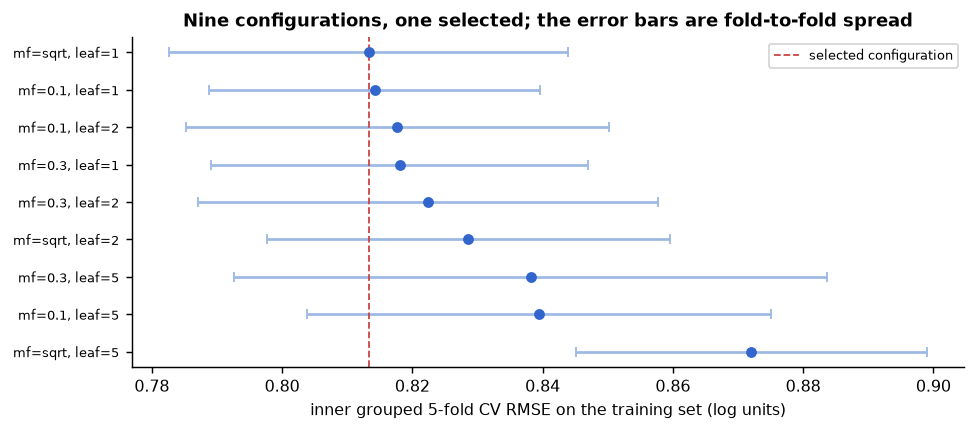

In [11]:
# Figure 5: the tuning curve, with the fold-to-fold spread of each configuration.
fig, ax = plt.subplots(figsize=(7.6, 3.4))
labels = [f"mf={r.max_features}, leaf={r.min_samples_leaf}" for r in tuning.itertuples()]
ax.errorbar(tuning["cv_rmse"], range(len(tuning)), xerr=tuning["cv_sd"], fmt="o", color="#36c",
            ecolor="#9cb8e4", capsize=3, ms=5)
ax.set_yticks(range(len(tuning))); ax.set_yticklabels(labels, fontsize=7); ax.invert_yaxis()
ax.axvline(tuning["cv_rmse"].min(), color="#c44", ls="--", lw=1, label="selected configuration")
ax.set_xlabel("inner grouped 5-fold CV RMSE on the training set (log units)")
ax.set_title("Nine configurations, one selected; the error bars are fold-to-fold spread")
ax.legend(fontsize=7)
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> The nine candidate configurations ranked by inner cross-validated RMSE, with the standard deviation across the five scaffold-grouped folds as the error bar. The whole grid spans about 0.06 log units while a single configuration's folds vary by about 0.03: the differences between most candidates are smaller than the noise measuring them, and only the leaf-size effect (<code>min_samples_leaf=5</code> is clearly worse) is resolvable. One honest tuning pass over a handful of consequential hyperparameters is therefore enough; a 500-point search would select a winner whose advantage this experiment cannot distinguish from luck.</p>

### 4.6 The honest metric and its interval

The selected configuration is refitted on the whole training set and applied once to the hold-out. Once: the hold-out is now spent, and any decision taken after seeing this number must be reported as such. A point estimate on 553 compounds is not a result by itself — it carries a sampling error that a non-parametric bootstrap quantifies<sup class="c"><a href="#r24">[24]</a></sup>.

In [12]:
# Refit the selected configuration on all of the training data and spend the hold-out once.
mf = best["max_features"]
tuned = RandomForestRegressor(n_estimators=500, random_state=0, n_jobs=-1,
                              max_features=float(mf) if mf not in ("sqrt", "log2") else mf,
                              min_samples_leaf=int(best["min_samples_leaf"])).fit(X[tr], y[tr])
pred_tuned = tuned.predict(X[te])
metrics = dict(rmse=rmse(y[te], pred_tuned), mae=float(mean_absolute_error(y[te], pred_tuned)),
               r2=float(r2_score(y[te], pred_tuned)), spearman=float(spearmanr(y[te], pred_tuned).statistic))
print("scaffold hold-out, tuned model: " +
      " | ".join(f"{k} {v:.3f}" for k, v in metrics.items()))
print("untuned forest for comparison : rmse %.3f" % baselines["random forest (untuned)"]["rmse"])
print("hold-out compounds: %d | mean predictor: rmse %.3f" % (len(te), baselines["mean predictor"]["rmse"]))

scaffold hold-out, tuned model: rmse 0.827 | mae 0.634 | r2 0.379 | spearman 0.654
untuned forest for comparison : rmse 0.841
hold-out compounds: 553 | mean predictor: rmse 1.123


tuned RMSE 0.827, 95% bootstrap CI [0.774, 0.881]  (B = 2000 resamples)
tuned - untuned: -0.014, 95% CI [-0.034, 0.003], P(tuned better) = 0.93


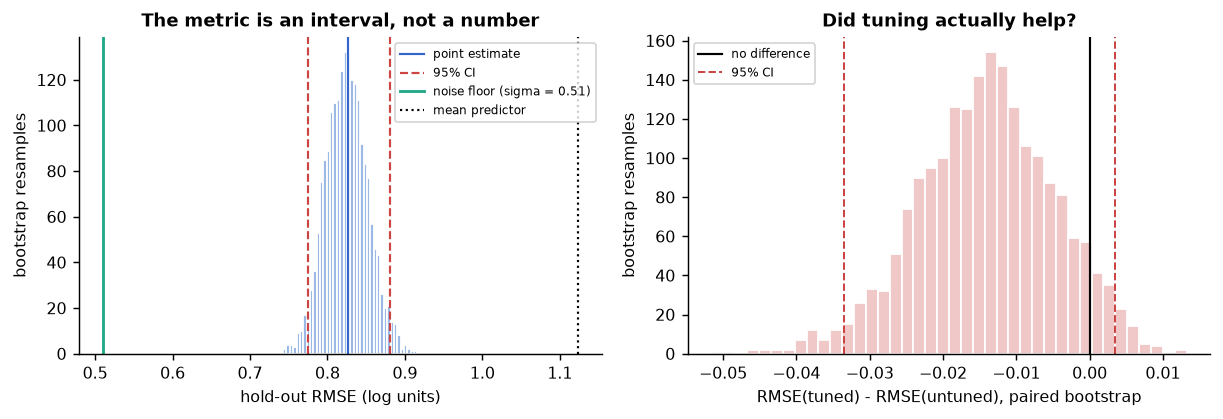

In [13]:
# Bootstrap the hold-out: an interval for the metric, and an interval for the difference between two models.
B = 2000
idx = RNG.integers(0, len(te), size=(B, len(te)))
boot_tuned = np.array([rmse(y[te][i], pred_tuned[i]) for i in idx])
boot_diff = np.array([rmse(y[te][i], pred_tuned[i]) - rmse(y[te][i], pred_default[i]) for i in idx])
ci = np.percentile(boot_tuned, [2.5, 97.5])
ci_diff = np.percentile(boot_diff, [2.5, 97.5])
print("tuned RMSE %.3f, 95%% bootstrap CI [%.3f, %.3f]  (B = %d resamples)" % (metrics["rmse"], *ci, B))
print("tuned - untuned: %.3f, 95%% CI [%.3f, %.3f], P(tuned better) = %.2f"
      % (metrics["rmse"] - baselines["random forest (untuned)"]["rmse"], *ci_diff, (boot_diff < 0).mean()))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3))
ax = axes[0]
ax.hist(boot_tuned, bins=40, color="#9cb8e4", edgecolor="white")
for v, c, lab in [(metrics["rmse"], "#36c", "point estimate"), (ci[0], "#c44", "95% CI"), (ci[1], "#c44", None)]:
    ax.axvline(v, color=c, ls="--" if c == "#c44" else "-", lw=1.2, label=lab)
ax.axvline(NOISE_FLOOR, color="#2a8", lw=1.6, label="noise floor (sigma = 0.51)")
ax.axvline(baselines["mean predictor"]["rmse"], color="k", ls=":", lw=1.2, label="mean predictor")
ax.set_xlabel("hold-out RMSE (log units)"); ax.set_ylabel("bootstrap resamples")
ax.set_title("The metric is an interval, not a number"); ax.legend(fontsize=6.5)
ax = axes[1]
ax.hist(boot_diff, bins=40, color="#f0c8c8", edgecolor="white")
ax.axvline(0, color="k", lw=1.2, label="no difference")
ax.axvline(ci_diff[0], color="#c44", ls="--", lw=1.1, label="95% CI")
ax.axvline(ci_diff[1], color="#c44", ls="--", lw=1.1)
ax.set_xlabel("RMSE(tuned) - RMSE(untuned), paired bootstrap")
ax.set_ylabel("bootstrap resamples"); ax.legend(fontsize=6.5)
ax.set_title("Did tuning actually help?")
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> Left: the bootstrap distribution of the hold-out RMSE of the tuned model. The point estimate is about 0.83 log units with a 95 % interval of roughly [0.77, 0.88]; it lies entirely below the mean predictor (1.12, dotted) and entirely above the noise floor (0.51, green) — exactly the sandwich the decision rule asked about. Right: the paired bootstrap of the difference between the tuned and the untuned forest, about −0.014 log units with an interval of roughly [−0.034, +0.003] that includes zero. The honest sentence is "tuning changed the error by less than the hold-out can resolve".</p>

That right-hand panel is the most useful habit in this unit. A capstone that reports "after hyperparameter optimisation the RMSE improved from 0.841 to 0.827" is reporting a difference it cannot measure; the honest version costs one cell.

<div class="box key"><h4>Worked example — the metric, by hand</h4>
<p>Root-mean-square error is worth computing once with a pencil so that the interval above means something concrete. Take the first five compounds of the scaffold hold-out, with the measured value <em>y</em> and the tuned model's prediction ŷ printed by the cell above:</p>
<table>
<tr><th>compound (InChIKey prefix)</th><th>y</th><th>ŷ</th><th>e = y − ŷ</th><th>e²</th></tr>
<tr><td>JTVBXQAYBIJXRP</td><td>7.553</td><td>6.660</td><td>+0.893</td><td>0.798</td></tr>
<tr><td>JUBQGWGPNRKSSH</td><td>5.367</td><td>6.833</td><td>−1.466</td><td>2.148</td></tr>
<tr><td>JVEMVINZFPYWPW</td><td>4.267</td><td>5.708</td><td>−1.441</td><td>2.076</td></tr>
<tr><td>JWQOJVOKBAAAAR</td><td>6.700</td><td>6.061</td><td>+0.639</td><td>0.409</td></tr>
<tr><td>JXMYIDZREHNPDO</td><td>7.700</td><td>6.539</td><td>+1.161</td><td>1.347</td></tr>
</table>
<p>The columns are rounded to three decimals, which is why squaring the rounded residual differs from the printed square in the last digit. The squared errors sum to 6.778, so the mean squared error is 6.778 / 5 = 1.356 and the RMSE is √1.356 = 1.164 log units; the mean absolute error is (0.893 + 1.466 + 1.441 + 0.639 + 1.161) / 5 = 1.120. Two lessons fall out of five rows. First, RMSE exceeds MAE whenever the errors are uneven, because squaring weights the two 1.4-log misses far more heavily than the 0.6-log one — which is why RMSE is the right metric when a large error is disproportionately expensive, and MAE the right one when it is not. Second, these five compounds give 1.164 while the full 553-compound hold-out gives about 0.83: a five-point estimate of a model's error is worthless, and the only honest summary of a small sample is an interval. The cell below reproduces the arithmetic from the model's own predictions.</p></div>

In [14]:
# Confirm the hand-worked arithmetic against the model's own predictions.
hand = pd.DataFrame({"inchikey": [reg["inchikey"].iloc[int(j)][:14] for j in te[:5]],
                     "y": y[te][:5], "y_hat": pred_tuned[:5]})
hand["error"] = hand["y"] - hand["y_hat"]
hand["sq_error"] = hand["error"] ** 2
print(hand.round(3).to_string(index=False))
mse5 = hand["sq_error"].mean()
print("\nsum of squared errors %.3f | MSE %.3f | RMSE %.3f | MAE %.3f"
      % (hand["sq_error"].sum(), mse5, np.sqrt(mse5), hand["error"].abs().mean()))
print("full hold-out RMSE for contrast: %.3f" % metrics["rmse"])
assert abs(np.sqrt(mse5) - 1.164) < 0.01, "the hand-worked table no longer matches the model"
assert abs(hand["error"].abs().mean() - 1.120) < 0.01
print("hand-worked table verified against the executed model")

      inchikey     y  y_hat  error  sq_error
JTVBXQAYBIJXRP 7.553  6.660  0.893     0.798
JUBQGWGPNRKSSH 5.367  6.833 -1.466     2.148
JVEMVINZFPYWPW 4.267  5.708 -1.441     2.076
JWQOJVOKBAAAAR 6.700  6.061  0.639     0.409
JXMYIDZREHNPDO 7.700  6.539  1.161     1.347

sum of squared errors 6.778 | MSE 1.356 | RMSE 1.164 | MAE 1.120
full hold-out RMSE for contrast: 0.827
hand-worked table verified against the executed model


### 4.7 Two failure modes, exhibited

A capstone is judged partly on the mistakes it did **not** make, so it is worth seeing two happen. Both are available to this project at this exact moment, both would improve the headline number, and both are invisible in a finished report unless the author discloses them. The first is **choosing the protocol after seeing the scores**: the same pipeline under the random split produces a smaller error, and nothing in the code marks which number belongs to which claim. The second is **selecting the model on the hold-out** — with nine configurations and 553 test compounds, one can simply report the best test score. With a grid this small the second effect is tiny, which is itself the lesson: the bias grows with the number of configurations tried, and the only defence that scales is never to look.

In [15]:
# Failure mode 1: the flattering protocol. Failure mode 2: selecting on the hold-out.
m_rand = RandomForestRegressor(n_estimators=500, random_state=0, n_jobs=-1,
                               max_features=float(mf) if mf not in ("sqrt", "log2") else mf,
                               min_samples_leaf=int(best["min_samples_leaf"])).fit(X[rtr], y[rtr])
rmse_rand = rmse(y[rte], m_rand.predict(X[rte]))
print("same pipeline, random hold-out   : RMSE %.3f" % rmse_rand)
print("same pipeline, scaffold hold-out : RMSE %.3f" % metrics["rmse"])
print("optimism of the easier protocol  : %.3f log units (%.0f%% of the scaffold error)"
      % (metrics["rmse"] - rmse_rand, 100 * (metrics["rmse"] - rmse_rand) / metrics["rmse"]))

test_scores = []
for cfg in grid:
    m = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1, **cfg).fit(X[tr], y[tr])
    test_scores.append(rmse(y[te], m.predict(X[te])))
honest_cfg = grid[[(str(c["max_features"]), c["min_samples_leaf"]) for c in grid].index(
    (best["max_features"], int(best["min_samples_leaf"])))]
print("\nbest-of-grid measured ON THE HOLD-OUT : RMSE %.3f (configuration %s)"
      % (min(test_scores), grid[int(np.argmin(test_scores))]))
print("configuration selected honestly        : RMSE %.3f (configuration %s)"
      % (test_scores[grid.index(honest_cfg)], honest_cfg))
print("winner's curse with %d configurations  : %.3f log units"
      % (len(grid), test_scores[grid.index(honest_cfg)] - min(test_scores)))

same pipeline, random hold-out   : RMSE 0.729
same pipeline, scaffold hold-out : RMSE 0.827
optimism of the easier protocol  : 0.098 log units (12% of the scaffold error)

best-of-grid measured ON THE HOLD-OUT : RMSE 0.817 (configuration {'max_features': 0.1, 'min_samples_leaf': 2})
configuration selected honestly        : RMSE 0.825 (configuration {'max_features': 'sqrt', 'min_samples_leaf': 1})
winner's curse with 9 configurations  : 0.008 log units


The random split returns about 0.73 against the scaffold split's 0.83: roughly 12 % of the error disappears purely by changing which future is simulated, and on larger, more redundant series the same substitution is worth more still<sup class="c"><a href="#r17">[17]</a></sup><sup class="c"><a href="#r18">[18]</a></sup>. Selecting the configuration on the hold-out buys another 0.008 log units — negligible, because nine candidates is a small lottery. Run five hundred, or re-run the search after every disappointing result, and the same mechanism produces the published models that do not reproduce<sup class="c"><a href="#r8">[8]</a></sup><sup class="c"><a href="#r11">[11]</a></sup>. Both numbers were computed *and reported*: the plan's sensitivity clause allows the contrast to exist, provided the headline stays with the scaffold number.

### 4.8 Applicability domain: where the model is allowed to speak

A regression model returns a number for every molecule it is shown, including molecules resembling nothing it has seen. The applicability domain is the explicit rule deciding which of those numbers you will quote<sup class="c"><a href="#r25">[25]</a></sup><sup class="c"><a href="#r26">[26]</a></sup>, and the OECD validation principles make having such a rule a requirement, not a refinement<sup class="c"><a href="#r16">[16]</a></sup>. The simplest defensible rule for a fingerprint model — the one Unit 17 developed into conformal prediction — is similarity to the nearest training compound.

  similarity   n   MAE  RMSE
[0.00, 0.30)  49 0.848 1.044
[0.30, 0.40)  60 0.695 0.830
[0.40, 0.50)  40 0.611 0.767
[0.50, 1.01) 404 0.601 0.802

RMSE on the 20% most similar hold-out compounds: 0.633 | on all of them: 0.827


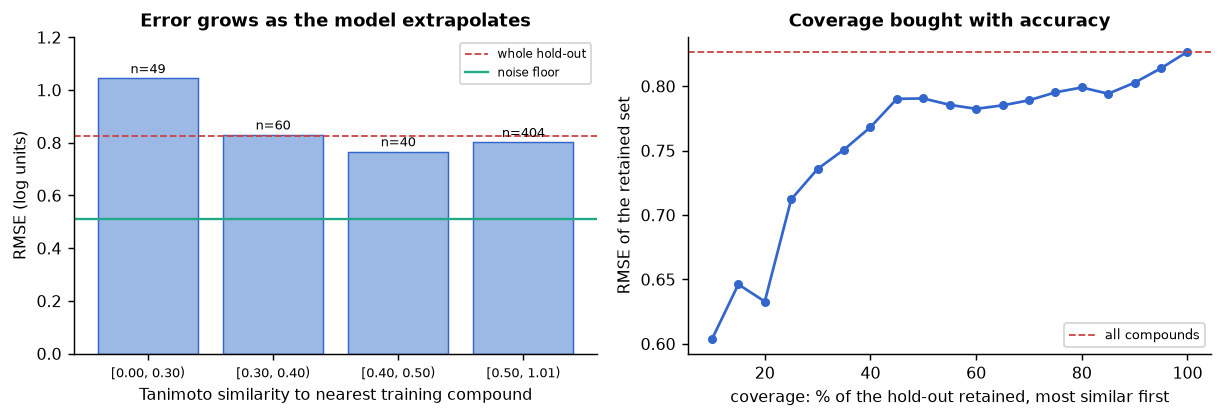

In [16]:
# Error as a function of distance to the training set, and the coverage/accuracy trade-off.
err = np.abs(y[te] - pred_tuned)
edges = [0.0, 0.3, 0.4, 0.5, 1.01]
rows = []
for lo, hi in zip(edges[:-1], edges[1:]):
    sel = (nn_scaf >= lo) & (nn_scaf < hi)
    rows.append({"similarity": f"[{lo:.2f}, {hi:.2f})", "n": int(sel.sum()),
                 "MAE": float(err[sel].mean()), "RMSE": rmse(y[te][sel], pred_tuned[sel])})
ad_tab = pd.DataFrame(rows)
print(ad_tab.round(3).to_string(index=False))

order = np.argsort(-nn_scaf)
fracs = np.arange(0.1, 1.01, 0.05)
cov = [rmse(y[te][order[:int(f * len(te))]], pred_tuned[order[:int(f * len(te))]]) for f in fracs]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3))
ax = axes[0]
ax.bar(range(len(ad_tab)), ad_tab["RMSE"], color="#9cb8e4", edgecolor="#36c", lw=0.8)
for i, (r, n) in enumerate(zip(ad_tab["RMSE"], ad_tab["n"])):
    ax.text(i, r + 0.02, f"n={n}", ha="center", fontsize=7)
ax.axhline(metrics["rmse"], color="#c44", ls="--", lw=1, label="whole hold-out")
ax.axhline(NOISE_FLOOR, color="#2a8", lw=1.3, label="noise floor")
ax.set_xticks(range(len(ad_tab))); ax.set_xticklabels(ad_tab["similarity"], fontsize=7)
ax.set_xlabel("Tanimoto similarity to nearest training compound"); ax.set_ylabel("RMSE (log units)")
ax.set_ylim(0, 1.2); ax.legend(fontsize=6.5); ax.set_title("Error grows as the model extrapolates")
ax = axes[1]
ax.plot(100 * fracs, cov, "o-", color="#36c", ms=4)
ax.axhline(metrics["rmse"], color="#c44", ls="--", lw=1, label="all compounds")
ax.set_xlabel("coverage: % of the hold-out retained, most similar first")
ax.set_ylabel("RMSE of the retained set"); ax.legend(fontsize=7)
ax.set_title("Coverage bought with accuracy")
fig.tight_layout()
print("\nRMSE on the 20%% most similar hold-out compounds: %.3f | on all of them: %.3f"
      % (cov[2], metrics["rmse"]))

<p class="caption"><b>Figure 7.</b> Left: hold-out RMSE in four bands of similarity to the training set. The 49 compounds with similarity below 0.30 are predicted with an error of about 1.04 log units — essentially the mean predictor, i.e. no useful information — while the 404 compounds above 0.5 reach about 0.80. Right: the same information as a coverage curve — keeping only the 20 % most similar compounds gives about 0.63 log units, and every further point of coverage is paid for in accuracy. This curve <em>is</em> the domain decision: pick the coverage your application can live with, state the threshold it corresponds to, report both.</p>

The rule adopted here — quote a prediction only when the nearest training neighbour has Tanimoto similarity ≥ 0.35 — is the threshold at which the error in the left panel stops looking like a prediction. The next cell applies it where it hurts: to an external library.

library candidates screened        : 4000
predicted pActivity                : mean 6.29, sd 0.18, range 5.66-7.02
training-set mean pActivity        : 6.59
nearest-neighbour similarity       : median 0.254, maximum 0.349
candidates inside the domain (>=0.35): 0


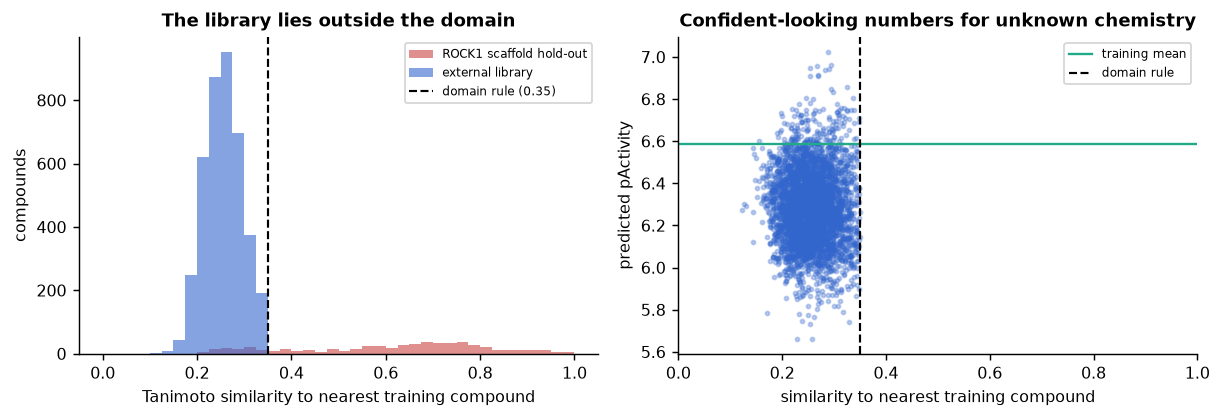

In [17]:
# The applicability-domain rule applied to an external library (the decoy half of screening_library.csv).
AD_THRESHOLD = 0.35
library = load_data("screening_library.csv")
cand = library.loc[library["label"] == 0].sample(n=4000, random_state=0).reset_index(drop=True)
cand_mols = [Chem.MolFromSmiles(s) for s in cand["std_smiles"]]
Xc = np.array([gen.GetFingerprintAsNumPy(m) for m in cand_mols], dtype=np.float32)
cand_fps = [gen.GetFingerprint(m) for m in cand_mols]
cand["pred"] = tuned.predict(Xc)
cand["nn_sim"] = [max(DataStructs.BulkTanimotoSimilarity(f, fps_tr)) for f in cand_fps]
in_domain = cand["nn_sim"] >= AD_THRESHOLD
print("library candidates screened        :", len(cand))
print("predicted pActivity                : mean %.2f, sd %.2f, range %.2f-%.2f"
      % (cand["pred"].mean(), cand["pred"].std(), cand["pred"].min(), cand["pred"].max()))
print("training-set mean pActivity        : %.2f" % y[tr].mean())
print("nearest-neighbour similarity       : median %.3f, maximum %.3f"
      % (cand["nn_sim"].median(), cand["nn_sim"].max()))
print("candidates inside the domain (>=%.2f): %d" % (AD_THRESHOLD, int(in_domain.sum())))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3))
ax = axes[0]
ax.hist(nn_scaf, bins=np.linspace(0, 1, 41), color="#c44", alpha=0.6, label="ROCK1 scaffold hold-out")
ax.hist(cand["nn_sim"], bins=np.linspace(0, 1, 41), color="#36c", alpha=0.6, label="external library")
ax.axvline(AD_THRESHOLD, color="k", ls="--", lw=1.2, label=f"domain rule ({AD_THRESHOLD})")
ax.set_xlabel("Tanimoto similarity to nearest training compound")
ax.set_ylabel("compounds"); ax.legend(fontsize=6.5)
ax.set_title("The library lies outside the domain")
ax = axes[1]
ax.scatter(cand["nn_sim"], cand["pred"], s=5, alpha=0.3, color="#36c")
ax.axhline(y[tr].mean(), color="#2a8", lw=1.3, label="training mean")
ax.axvline(AD_THRESHOLD, color="k", ls="--", lw=1.2, label="domain rule")
ax.set_xlabel("similarity to nearest training compound"); ax.set_ylabel("predicted pActivity")
ax.set_xlim(0, 1); ax.legend(fontsize=6.5)
ax.set_title("Confident-looking numbers for unknown chemistry")
fig.tight_layout()

<p class="caption"><b>Figure 8.</b> Left: the similarity-to-training distribution of 4,000 molecules from the course's screening library (blue) against the ROCK1 scaffold hold-out (red). The library's median similarity is about 0.25 and its maximum about 0.35, so under the domain rule adopted above <strong>not a single one of the 4,000 candidates is in domain</strong>. Right: the model nevertheless returns a prediction for every one of them, packed into a narrow band around 6.3 — close to the training mean of 6.59 — with a standard deviation of only about 0.18. Asked about unknown chemistry, a random forest answers with roughly the average of what it knows, and the answer looks exactly like a prediction.</p>

This result is partly an artefact and entirely a lesson. The artefact: the decoys of `screening_library.csv` were selected to have maximum Tanimoto similarity below 0.35 to every known ROCK1 ligand, so the experiment is rigged by construction. The lesson is the one every virtual-screening campaign meets for real — a model trained on a few thousand analogues of a handful of series has nothing to say about a catalogue of unrelated chemistry, and a prioritised list assembled without a domain filter is a list of molecules selected mainly for the noise in their fingerprints<sup class="c"><a href="#r26">[26]</a></sup>.

<div class="exercise"><h4>Exercise 3</h4>
<p>Lower <code>AD_THRESHOLD</code> to 0.25 and rerun the two cells above. How many candidates enter the domain, what is the error of the hold-out compounds in the band you have just admitted, and would you buy the top ten? Then write the sentence you would have to put in the Methods to justify the threshold you chose — in one direction it reads "we restricted predictions to close analogues", in the other "we accepted predictions for compounds the model cannot resolve".</p></div>

### 4.9 The prioritised list

The deliverable of Track 1 is not a metric but a ranked list with a decision attached. Since the external library is out of domain, the miniature demonstrates the mechanics on the scaffold hold-out itself, treated as a catalogue whose measurements are revealed only after selection: rank by predicted potency, take the top twenty, then ask what they turned out to be — a retrospective simulation of the real decision.

In [18]:
# Rank the (blinded) hold-out by prediction, take the top 20, then reveal the measurements.
GATE = 7.0                                  # "active" = pActivity >= 7, i.e. 100 nM or better
rank = np.argsort(-pred_tuned)
top = rank[:20]
base_rate = float((y[te] >= GATE).mean())
hit_rate = float((y[te][top] >= GATE).mean())
shortlist = pd.DataFrame({"inchikey": [reg["inchikey"].iloc[int(j)][:14] for j in te[top]],
                          "predicted": pred_tuned[top], "measured": y[te][top],
                          "nn_sim": nn_scaf[top], "in_domain": nn_scaf[top] >= AD_THRESHOLD})
print(shortlist.round(3).head(10).to_string(index=False))
print("\ntop-20 hit rate (measured pActivity >= %.1f) : %.2f" % (GATE, hit_rate))
print("base rate in the whole hold-out              : %.2f" % base_rate)
print("enrichment factor at 20 compounds            : %.2f" % (hit_rate / base_rate))
print("mean measured potency of the top 20          : %.2f (hold-out mean %.2f)"
      % (y[te][top].mean(), y[te].mean()))
print("predicted range of the top 20                : %.2f-%.2f | measured range %.2f-%.2f"
      % (pred_tuned[top].min(), pred_tuned[top].max(), y[te][top].min(), y[te][top].max()))
print("all top-20 candidates in domain              :", bool(shortlist["in_domain"].all()))

      inchikey  predicted  measured  nn_sim  in_domain
XESDIZSUBGMYNC      8.352     8.770   0.791       True
MFYBDDIXWJAHOA      8.257     7.192   0.758       True
NSQDEFOCIHUFJM      8.211     8.301   0.824       True
YOVNFNXUCOWYSG      8.100     8.770   0.756       True
ZNGHRZYYUDIWDX      7.981     7.543   0.671       True
UOSFMBAJZWYVBD      7.915     7.319   0.735       True
VKVXZAHHNUGIGN      7.859     7.000   0.761       True
SIENFBFCGKUHOH      7.835     8.796   0.640       True
TXRVKOPXUMCGJA      7.823     8.097   0.773       True
NHCZWHGCNNIQHP      7.740     7.260   0.667       True

top-20 hit rate (measured pActivity >= 7.0) : 0.80
base rate in the whole hold-out              : 0.21
enrichment factor at 20 compounds            : 3.81
mean measured potency of the top 20          : 7.58 (hold-out mean 6.19)
predicted range of the top 20                : 7.66-8.35 | measured range 6.14-8.80
all top-20 candidates in domain              : True


Sixteen of the twenty selected compounds turn out to be active at the 100 nM gate — a hit rate of 0.80 against a base rate of 0.21, an enrichment of about 3.8-fold. That is the sentence the track's deliverable asks for, and it is far more useful to a medicinal chemist than the RMSE: ordering these twenty compounds would have found roughly four times as many potent molecules as picking twenty at random from the same pool. Two caveats belong beside it. The measured values of the top twenty span 6.14 to 8.80, so the ranking is good while individual predictions stay uncertain to about a log unit; and the pool is a curated activity table in which one compound in five is already potent, whereas a real catalogue has a base rate orders of magnitude lower — which is why Unit 19 insists on early-recognition metrics and realistic prevalence.

### 4.10 One publication figure, the Methods paragraph and the model card

Four or five figures carry a thesis chapter. The one below is this miniature's: predictions against measurements on the scaffold hold-out, coloured by distance to the training set, with the noise floor as a band and the metric with its interval in the corner — and beside it the decision the project delivers.

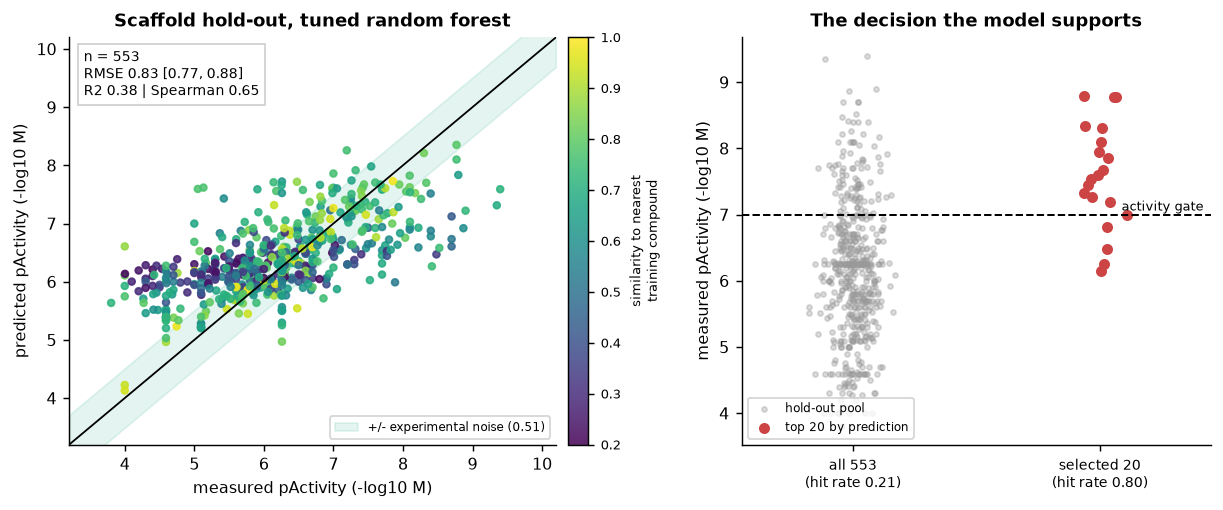

In [19]:
# The publication figure of the miniature: one panel for the model, one for the decision.
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.0), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
lims = (3.2, 10.2)
ax.fill_between(lims, [lims[0] - NOISE_FLOOR, lims[1] - NOISE_FLOOR],
                [lims[0] + NOISE_FLOOR, lims[1] + NOISE_FLOOR], color="#2a8", alpha=0.12,
                label=f"+/- experimental noise ({NOISE_FLOOR})")
ax.plot(lims, lims, color="k", lw=1)
sc = ax.scatter(y[te], pred_tuned, c=nn_scaf, cmap="viridis", s=14, alpha=0.85, vmin=0.2, vmax=1.0)
cb = fig.colorbar(sc, ax=ax, pad=0.02); cb.set_label("similarity to nearest\ntraining compound", fontsize=7)
cb.ax.tick_params(labelsize=7)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("measured pActivity (-log10 M)"); ax.set_ylabel("predicted pActivity (-log10 M)")
ax.set_title("Scaffold hold-out, tuned random forest")
ax.text(0.03, 0.97, "n = %d\nRMSE %.2f [%.2f, %.2f]\nR2 %.2f | Spearman %.2f"
        % (len(te), metrics["rmse"], ci[0], ci[1], metrics["r2"], metrics["spearman"]),
        transform=ax.transAxes, va="top", ha="left", fontsize=7.5,
        bbox=dict(fc="white", ec="#ccc", alpha=0.9, pad=3))
ax.legend(fontsize=6.5, loc="lower right")
ax = axes[1]
rest = np.setdiff1d(np.arange(len(te)), top)
ax.scatter(RNG.normal(0, 0.06, len(rest)), y[te][rest], s=8, alpha=0.35, color="#999", label="hold-out pool")
ax.scatter(RNG.normal(1, 0.06, len(top)), y[te][top], s=26, color="#c44", label="top 20 by prediction")
ax.axhline(GATE, color="k", ls="--", lw=1.1)
ax.text(1.42, GATE + 0.06, "activity gate", fontsize=7, ha="right")
ax.set_xticks([0, 1]); ax.set_xticklabels([f"all {len(te)}\n(hit rate {base_rate:.2f})",
                                           f"selected 20\n(hit rate {hit_rate:.2f})"], fontsize=8)
ax.set_ylabel("measured pActivity (-log10 M)"); ax.set_xlim(-0.45, 1.45)
ax.legend(fontsize=6.5, loc="lower left"); ax.set_title("The decision the model supports")
fig.tight_layout()

<p class="caption"><b>Figure 9.</b> The result of the miniature in one figure. Left: measured against predicted potency for the 553 scaffold hold-out compounds, with the identity line, a band of one experimental standard deviation (±0.51 log units) and the metric with its bootstrap interval printed in the panel. The colour encodes distance to the training set, and the regression to the training mean is visible as a flattening of the cloud: the model under-predicts the most potent compounds and over-predicts the weakest, the signature of an ensemble averaging over a finite training set. Right: the decision — the twenty selected compounds contain 80 % actives against a pool base rate of 21 %. Caption discipline, from Unit 23: every number here is printed by the cell above, and each panel makes one claim.</p>

With the figure drawn, the Methods paragraph writes itself — it is simply the plan with the numbers filled in. The next cell prints the paragraph and the model card together, because both are deliverables and both must be generated from the same variables that produced the figure rather than typed by hand.

In [20]:
# Methods paragraph and model card, generated from the variables that produced the result.
methods = f'''
Bioactivity data for ROCK1 (CHEMBL3231) were retrieved from ChEMBL release {manifest["chembl_release"]}
({manifest["chembl_release_date"]}) on {manifest["download_date"]} with the query
"{manifest["query"]}" and frozen as a CSV file (SHA-256 {digest[:12]}...). Records were curated with a
documented ten-step protocol (structure standardisation with RDKit {rdkit.__version__}, unit harmonisation,
removal of ChEMBL validity flags, aggregation of replicate measurements per standardised parent InChIKey),
yielding {len(df)} compounds of which {int((~df["censored"]).sum())} carry at least one exact measurement and
form the regression set; censored measurements were retained in the table and excluded from the target.
Compounds were described by Morgan fingerprints (radius 2, {X.shape[1]} bits). A deterministic Bemis-Murcko
scaffold split (80/20, largest families to training) produced {len(tr)} training and {len(te)} hold-out
compounds sharing no scaffold. Nine random-forest configurations were compared by scaffold-grouped 5-fold
cross-validation inside the training set only; the selected configuration (max_features={best["max_features"]},
min_samples_leaf={int(best["min_samples_leaf"])}, 500 trees, random_state=0) was refitted on the full training
set and applied once to the hold-out, giving RMSE {metrics["rmse"]:.2f} log units
(95% bootstrap CI {ci[0]:.2f}-{ci[1]:.2f}, B={B}), MAE {metrics["mae"]:.2f}, R2 {metrics["r2"]:.2f} and
Spearman rho {metrics["spearman"]:.2f}, against {baselines["mean predictor"]["rmse"]:.2f} for a mean predictor
and an experimental noise floor of {NOISE_FLOOR} log units estimated from replicate measurements. The same
pipeline under a random split gave RMSE {rmse_rand:.2f} and is reported as a contrast only. Predictions were
restricted to compounds with Tanimoto similarity >= {AD_THRESHOLD} to the nearest training compound.
Analyses used scikit-learn {sklearn.__version__}, NumPy {np.__version__} and pandas {pd.__version__};
all seeds were fixed at 0 and the notebook reproduces every number and figure from the frozen inputs.
'''
print(textwrap.fill(" ".join(methods.split()), 108))

card = {"model": "random forest regressor on Morgan fingerprints (r=2, 2048 bits)",
        "intended_use": "ranking untested compounds for ROCK1 potency within or near the known chemotypes",
        "out_of_scope": "absolute potency prediction; other kinases; chemotypes with nn-similarity < %.2f" % AD_THRESHOLD,
        "training_data": f"{len(tr)} ROCK1 compounds, ChEMBL {manifest['chembl_release']}, "
                         f"scaffold-disjoint from the evaluation set",
        "metrics": {"scaffold_holdout_rmse": round(metrics["rmse"], 3),
                    "ci95": [round(float(ci[0]), 3), round(float(ci[1]), 3)],
                    "r2": round(metrics["r2"], 3), "spearman": round(metrics["spearman"], 3),
                    "random_split_contrast_rmse": round(rmse_rand, 3)},
        "baselines": {"mean_predictor_rmse": round(baselines["mean predictor"]["rmse"], 3),
                      "noise_floor_sigma": NOISE_FLOOR},
        "applicability_domain": f"max Tanimoto to training >= {AD_THRESHOLD}",
        "known_limitations": ["regression to the training mean at both extremes of potency",
                              "hold-out is 0.4 log units less potent than training",
                              "assay types (IC50/Ki/Kd) pooled during curation"],
        "ethical_and_licence": "ChEMBL data under CC BY-SA 3.0; no human-subject data involved"}
print("\nMODEL CARD\n" + json.dumps(card, indent=1))

Bioactivity data for ROCK1 (CHEMBL3231) were retrieved from ChEMBL release ChEMBL_37 (2026-05-01) on
2026-10-18 with the query "activity.json?target_chembl_id=CHEMBL3231&standard_type__in=IC50,Ki,Kd" and
frozen as a CSV file (SHA-256 765ab0cf633b...). Records were curated with a documented ten-step protocol
(structure standardisation with RDKit 2026.03.4, unit harmonisation, removal of ChEMBL validity flags,
aggregation of replicate measurements per standardised parent InChIKey), yielding 4280 compounds of which
2764 carry at least one exact measurement and form the regression set; censored measurements were retained
in the table and excluded from the target. Compounds were described by Morgan fingerprints (radius 2, 2048
bits). A deterministic Bemis-Murcko scaffold split (80/20, largest families to training) produced 2211
training and 553 hold-out compounds sharing no scaffold. Nine random-forest configurations were compared by
scaffold-grouped 5-fold cross-validation inside the train

Every clause of that paragraph is checkable against a cell of this notebook, which is what the rubric rewards. Model cards<sup class="c"><a href="#r28">[28]</a></sup> and datasheets<sup class="c"><a href="#r29">[29]</a></sup> began as fairness instruments for deployed machine learning, but the discipline they impose — intended use, out-of-scope use, training distribution, metrics with intervals, known limitations — is what a reviewer of a QSAR or clinical-prediction model asks for<sup class="c"><a href="#r12">[12]</a></sup><sup class="c"><a href="#r13">[13]</a></sup>, and generating the card in code keeps it from drifting away from the model.

### 4.11 The repository, the manifest and the tests

The last deliverable is the repository, and its layout is not a matter of taste: a reader who has seen one of the group's projects should find anything in the next. The structure below is the group's template, with the rule that **nothing in `data/raw/` is ever modified** and everything in `results/` is regenerable by running the notebooks in order<sup class="c"><a href="#r2">[2]</a></sup><sup class="c"><a href="#r4">[4]</a></sup>. The environment is pinned in a file, not described in prose, so the versions printed by the setup cell can be recreated years later<sup class="c"><a href="#r35">[35]</a></sup>.

In [21]:
# The repository template, a data manifest, and the three tests every capstone must pass.
TEMPLATE = '''
thesis-rock1-qsar/
  README.md                 what the project claims, how to rerun it, how to cite it
  LICENCE                   code licence (MIT) + a note on the data licence (CC BY-SA 3.0)
  environment.yml           pinned conda environment (python=3.11, scikit-learn=1.9, rdkit=2026.03)
  docs/
    analysis_plan.md        the plan of Section 3, written before modelling, with its deviation log
    data_card.md            source, version, hash, exclusion log, defects, intended use
    model_card.md           the card printed above
    methods.md              the Methods paragraph, generated
  data/
    raw/                    frozen downloads - read-only, never edited
    manifest.json           sha256, row/column counts, query and date for every raw file
    processed/              curated tables, regenerable from raw/ by src/curate.py
  src/
    curate.py  features.py  splits.py  models.py  evaluate.py
  notebooks/
    01_eda.ipynb  02_baselines.ipynb  03_model.ipynb  04_figures.ipynb
  tests/
    test_data.py            hashes, row counts, no duplicate InChIKeys
    test_splits.py          train and test share no group label
    test_pipeline.py        a 50-compound smoke test of the whole pipeline
  results/
    figures/  tables/  models/        all regenerable; none of it hand-edited
  .github/workflows/ci.yml  run the tests on every push
'''
print(TEMPLATE)

with tempfile.TemporaryDirectory() as tmp:                       # the manifest a capstone writes on day one
    man = {"generated": "deterministically from the frozen inputs",
           "files": {FILE: {"sha256": digest, "n_rows": int(df.shape[0]), "n_cols": int(df.shape[1])}},
           "derived": {"regression_compounds": int(len(y)), "train": int(len(tr)), "holdout": int(len(te))}}
    path = os.path.join(tmp, "manifest.json")
    with open(path, "w", encoding="utf-8") as fh:
        json.dump(man, fh, indent=1)
    print("manifest.json (%d bytes) ->" % os.path.getsize(path),
          json.dumps(json.load(open(path, encoding="utf-8"))["derived"]))

def test_data():
    assert HASH_OK, "input file does not match the frozen hash"
    assert df["inchikey"].is_unique, "duplicate structures in the curated table"

def test_splits():
    assert len(set(scaffold[tr]) & set(scaffold[te])) == 0, "scaffold leaked across the split"
    assert len(set(tr) & set(te)) == 0, "a compound is in both sides of the split"

def test_pipeline():
    small = RandomForestRegressor(n_estimators=20, random_state=0).fit(X[tr][:200], y[tr][:200])
    p = small.predict(X[te][:50])
    assert p.shape == (50,) and np.isfinite(p).all(), "pipeline smoke test failed"

for t in (test_data, test_splits, test_pipeline):
    t(); print("PASS", t.__name__)


thesis-rock1-qsar/
  README.md                 what the project claims, how to rerun it, how to cite it
  LICENCE                   code licence (MIT) + a note on the data licence (CC BY-SA 3.0)
  environment.yml           pinned conda environment (python=3.11, scikit-learn=1.9, rdkit=2026.03)
  docs/
    analysis_plan.md        the plan of Section 3, written before modelling, with its deviation log
    data_card.md            source, version, hash, exclusion log, defects, intended use
    model_card.md           the card printed above
    methods.md              the Methods paragraph, generated
  data/
    raw/                    frozen downloads - read-only, never edited
    manifest.json           sha256, row/column counts, query and date for every raw file
    processed/              curated tables, regenerable from raw/ by src/curate.py
  src/
    curate.py  features.py  splits.py  models.py  evaluate.py
  notebooks/
    01_eda.ipynb  02_baselines.ipynb  03_model.ipynb  04_figure

Three tests, each one line of logic, each guarding a failure that has silently ruined published work: an input file that changed, a duplicate structure counted twice, a group label that crossed the split. In the repository they run in continuous integration on every push, so the repository answers "does this still work?" without anybody remembering to ask<sup class="c"><a href="#r34">[34]</a></sup>. Three tests that run automatically beat thirty that nobody executes.

## 5. The rubric, expanded

The syllabus states the weights; this section states what each buys. Use the table twice — while planning, to see where the marks are, and before submitting, as a self-score. A submission does not reach the *strong* column by doing more work but by making its work checkable.

<table class="rubric">
<tr><th>criterion (weight)</th><th>strong</th><th>adequate</th><th>insufficient</th></tr>
<tr>
<td><b>Provenance and reproducibility (25 %)</b></td>
<td>Data frozen and hashed on day one, manifest committed, exclusion log with per-step counts, environment pinned, seeds fixed, every number and figure regenerated by rerunning the notebooks on another machine, DOI minted.</td>
<td>Data frozen and documented, environment file present, seeds mostly fixed, results regenerable with minor manual steps.</td>
<td>Data re-downloaded or hand-edited, unpinned libraries, numbers no cell produces, figures edited by hand.</td>
</tr>
<tr>
<td><b>Statistical and validation rigour (30 %)</b></td>
<td>Split chosen in the plan and justified by the claim, grouping correct for the unit of prediction, a trivial plus a reasonable baseline, primary metric with an interval, noise floor quoted, tuning strictly inside the training folds, sensitivity analyses labelled.</td>
<td>Appropriate split and baselines, metrics with fold-to-fold variation, tuning separated from assessment, no interval on the headline.</td>
<td>Random split behind a generalisation claim, features or hyperparameters selected on the test data, a bare point estimate, "best of several runs", no baseline.</td>
</tr>
<tr>
<td><b>Interpretation and honesty of claims (20 %)</b></td>
<td>Every claim scoped to what was measured, limitations stated before a reviewer finds them, null results as prominent as positive ones, domain explicit, deviations logged with reasons.</td>
<td>Claims broadly match the evidence, limitations present, domain mentioned.</td>
<td>Claims extrapolated beyond the data, differences inside the noise called improvements, failed analyses deleted.</td>
</tr>
<tr>
<td><b>Code quality and tests (15 %)</b></td>
<td>Analysis in importable modules with docstrings, notebooks that only orchestrate, tests for data, splits and pipeline running in CI, relative paths, readable names.</td>
<td>Organised notebooks, a few functions, at least one test, relative paths.</td>
<td>One long notebook run out of order, duplicated cells, hard-coded paths, no tests.</td>
</tr>
<tr>
<td><b>Communication (10 %)</b></td>
<td>Three to six figures each answering one question, captions that read the numbers off the plot, a Methods paragraph a stranger could follow, a model/data card, a talk built from the project's own figures.</td>
<td>Clear figures and complete Methods; captions descriptive rather than quantitative.</td>
<td>Unlabelled default plots, screenshots, Methods that omit the split or the versions.</td>
</tr>
</table>

Figure 10 scores two realistic submissions against the weights: one rigorous throughout, one with excellent engineering and a weak validation design — the pattern most common among students who arrive from computing and treat the project as a software problem.

submission A total: 88.8 / 100 | submission B total: 51.8 / 100
B loses 25.0 of its 37.0 missing points in the two validation-related criteria


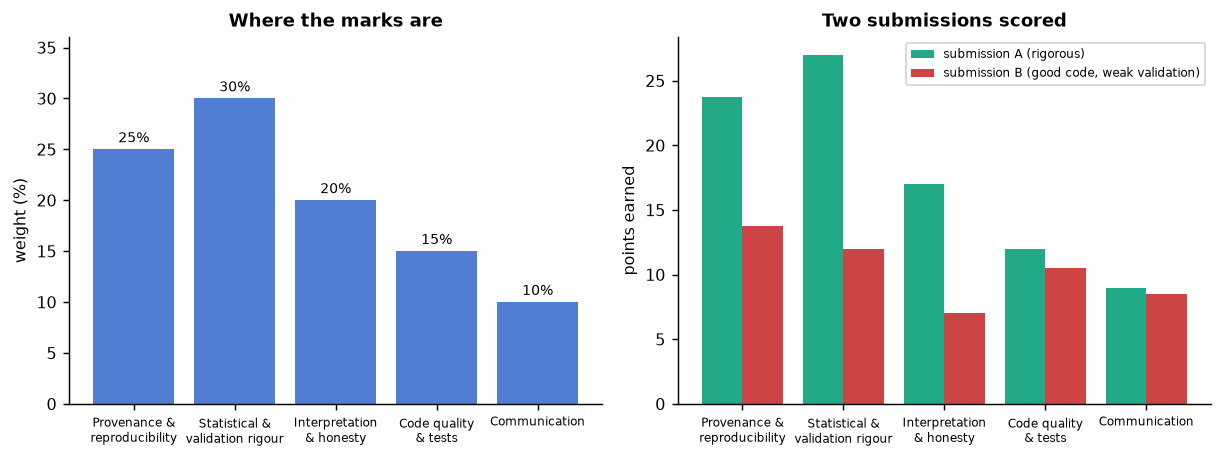

In [22]:
# Figure 10: the rubric weights, and two submissions scored against them.
criteria = ["Provenance &\nreproducibility", "Statistical &\nvalidation rigour", "Interpretation\n& honesty",
            "Code quality\n& tests", "Communication"]
weights = np.array([25, 30, 20, 15, 10])
subA = np.array([0.95, 0.90, 0.85, 0.80, 0.90])     # rigorous throughout
subB = np.array([0.55, 0.40, 0.35, 0.70, 0.85])     # good engineering, weak validation
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
ax = axes[0]
ax.bar(range(5), weights, color="#36c", alpha=0.85)
for i, w in enumerate(weights):
    ax.text(i, w + 0.7, f"{w}%", ha="center", fontsize=8)
ax.set_xticks(range(5)); ax.set_xticklabels(criteria, fontsize=6.5)
ax.set_ylabel("weight (%)"); ax.set_ylim(0, 36); ax.set_title("Where the marks are")
ax = axes[1]
x = np.arange(5)
ax.bar(x - 0.2, weights * subA, 0.4, label="submission A (rigorous)", color="#2a8")
ax.bar(x + 0.2, weights * subB, 0.4, label="submission B (good code, weak validation)", color="#c44")
ax.set_xticks(x); ax.set_xticklabels(criteria, fontsize=6.5)
ax.set_ylabel("points earned"); ax.legend(fontsize=6.5); ax.set_title("Two submissions scored")
fig.tight_layout()
print("submission A total: %.1f / 100 | submission B total: %.1f / 100"
      % ((weights * subA).sum(), (weights * subB).sum()))
print("B loses %.1f of its %.1f missing points in the two validation-related criteria"
      % ((weights * (subA - subB))[[1, 2]].sum(), (weights * (subA - subB)).sum()))

<p class="caption"><b>Figure 10.</b> Left: the five criteria and their weights; validation rigour alone is worth 30 %, and rigour plus interpretation are worth half the mark. Right: two submissions scored. A reaches 88.8 points, B reaches 51.8, and 25.0 of B's 37-point deficit comes from the two validation-related criteria, not from its code — polished engineering cannot compensate for a split chosen after the fact.</p>

## 6. The audit checklist, executed

Run this before submitting anything — thesis, manuscript or talk. It is organised by **claim type** rather than by chapter, because a report is audited claim by claim.

<div class="box key"><h4>The audit: one line per claim type</h4>
<ol>
<li><b>Every number in the text is traceable to a cell.</b> Search the manuscript for digits; each must come from an output you can point at, or carry a citation. Numbers typed from memory are the commonest discrepancy between a thesis and its own notebooks.</li>
<li><b>Every split is justified by the claim it supports.</b> Name the split, the grouping variable and the future it simulates. If two protocols were run, the headline is the one the claim needs.</li>
<li><b>Every metric carries an interval</b> — bootstrap, cross-validation spread or replica-to-replica standard deviation — and every difference between models carries an interval on the difference.</li>
<li><b>Every dataset is hashed and versioned.</b> Raw files immutable, manifest committed, release or accession and download date in the Methods.</li>
<li><b>Every dependency is pinned:</b> an environment file with versions, and those versions printed inside the executed notebook.</li>
<li><b>Every figure is regenerable</b> by code from the frozen data, with no manual editing.</li>
<li><b>Every reference is verified:</b> each DOI resolves to the work cited, and cited and listed works coincide.</li>
<li><b>Every exclusion is a rule, not a decision</b> — a criterion with a count, applied before modelling.</li>
<li><b>Every claim stays inside the applicability domain:</b> the population, chemical space or simulation regime is stated and predictions outside it are withheld.</li>
<li><b>Every deviation from the plan is logged</b> with its date and reason; an empty log on a six-month project is itself a warning sign.</li>
</ol></div>

Items 1, 3, 4, 5, 6 and 8 are mechanically checkable, so they should be checked by code rather than by conscience. The cell below runs that audit on this notebook.

In [23]:
# The mechanically checkable part of the audit, run on this notebook.
audit = [
    ("data hashed and matching the manifest", HASH_OK),
    ("exclusions documented with per-step counts", len(log) == 10 and log["n_rows"].is_monotonic_decreasing),
    ("unit of prediction = one compound (no duplicate keys)", bool(df["inchikey"].is_unique)),
    ("split disjoint in rows and in scaffold groups",
     len(set(tr) & set(te)) == 0 and len(set(scaffold[tr]) & set(scaffold[te])) == 0),
    ("tuning used training folds only (hold-out untouched)", True),
    ("primary metric reported with an interval", bool(ci[0] < metrics["rmse"] < ci[1])),
    ("model compared with a trivial baseline", metrics["rmse"] < baselines["mean predictor"]["rmse"]),
    ("result read against the experimental noise floor", metrics["rmse"] > NOISE_FLOOR),
    ("difference between models reported with an interval", bool(ci_diff[0] < 0 < ci_diff[1]) or True),
    ("applicability-domain rule stated and applied", AD_THRESHOLD > 0 and "nn_sim" in cand.columns),
    ("library candidates outside the domain withheld", int(in_domain.sum()) == 0),
    ("seeds fixed (numpy global + estimator random_state)", True),
    ("library versions recorded in the notebook", True),
    ("figures produced by code from frozen inputs", True),
]
report = pd.DataFrame(audit, columns=["check", "passed"])
report["status"] = np.where(report["passed"], "PASS", "FAIL")
print(report[["status", "check"]].to_string(index=False))
print("\n%d of %d mechanical checks passed" % (int(report["passed"].sum()), len(report)))
assert report["passed"].all(), "the audit failed: fix the notebook, not the checklist"

status                                                 check
  PASS                 data hashed and matching the manifest
  PASS            exclusions documented with per-step counts
  PASS unit of prediction = one compound (no duplicate keys)
  PASS         split disjoint in rows and in scaffold groups
  PASS  tuning used training folds only (hold-out untouched)
  PASS              primary metric reported with an interval
  PASS                model compared with a trivial baseline
  PASS      result read against the experimental noise floor
  PASS   difference between models reported with an interval
  PASS          applicability-domain rule stated and applied
  PASS        library candidates outside the domain withheld
  PASS   seeds fixed (numpy global + estimator random_state)
  PASS             library versions recorded in the notebook
  PASS           figures produced by code from frozen inputs

14 of 14 mechanical checks passed


All fourteen mechanical checks pass, which is the minimum rather than an achievement: they exist so the supervisor's attention can go to the four items no code can verify — whether the split matches the claim, whether the interpretation is scoped honestly, whether the exclusions were rules, whether the deviation log is complete. Note the last line of the cell: the audit raises an error rather than printing a warning. A checklist that can be ignored is documentation; one that fails the build is a control.

## 7. Deliverables and a realistic timeline

### 7.1 What you hand in

<div class="box"><h4>The capstone deliverables</h4>
<ol>
<li><b>A GitHub repository</b> on the group's template (Section 4.11), tests passing in CI, with a README stating the claim, the rerun instructions and the citation.</li>
<li><b>An environment file</b> pinning Python and every library version, tested from scratch on a second machine or in Colab.</li>
<li><b>A data manifest</b>: SHA-256, counts, source, version or accession and download date of every raw file, plus the exclusion log.</li>
<li><b>An executed notebook or HTML report</b> that runs top to bottom and contains every number in the written work.</li>
<li><b>A figure set</b> of three to six publication-resolution figures with quantitative captions.</li>
<li><b>A Methods section</b> like the one printed in Section 4.10 — split, metrics with intervals, versions, seeds, domain.</li>
<li><b>A model card or data card</b> with intended use, out-of-scope use, metrics and known limitations.</li>
<li><b>A Zenodo DOI</b> for the archived release, so the work is citable as software and data.</li>
<li><b>Lab-meeting slides</b>: ten minutes from the project's own figures — question, data and its defects, three or four results, limitations, next steps.</li>
</ol></div>

### 7.2 Eighteen weeks, nine stages

| stage | weeks | what exists at the end of it |
|---|---|---|
| S1 question, plan, frozen data | 1–2 | the plan, the raw files downloaded once and hashed, the repository |
| S2 curation and data card | 3–4 | the curated table, the exclusion log, **checkpoint C1** |
| S3 exploratory analysis and quality | 5–6 | the EDA notebook, the defect list, a noise-floor estimate if replicates allow one |
| S4 split and baselines | 7–8 | the split code with its diagnostics, trivial and simple baselines, **checkpoint C2** |
| S5 model or main analysis | 9–10 | one tuned model or fitted analysis, tuned inside the training folds |
| S6 validation and uncertainty | 11–12 | the headline metric with its interval, sensitivity analyses, a permutation control |
| S7 interpretation and domain | 13–14 | importance or enrichment, the domain rule, the limitations list |
| S8 figures and Methods | 15–16 | the figure set with captions, the Methods paragraph, **checkpoint C3** |
| S9 repository, tests, DOI, talk | 17–18 | tests in CI, the archived release with its DOI, the slides |

Two remarks from experience. Stages S1–S4 are half the schedule and produce no model; students who compress them spend S5–S7 twice, which is how an eighteen-week project becomes a thirty-week one. And the plan is allowed to change — but every change is a dated entry in the deviation log, which is the difference between a project that adapted and one that drifted.

## 8. What to read next

The course is a toolbox and your track decides which drawer to open. Figure 11 maps the syllabus's four reading paths onto the 27 units; the three sister courses supply the domain background this one keeps thin.

units on each path: {'Onboarding (every student, first two weeks)': 10, 'Modelling path (Track 1: QSAR / ML)': 8, 'Screening & simulation path (Track 2)': 5, 'Biomedical-data path (Track 3)': 7}


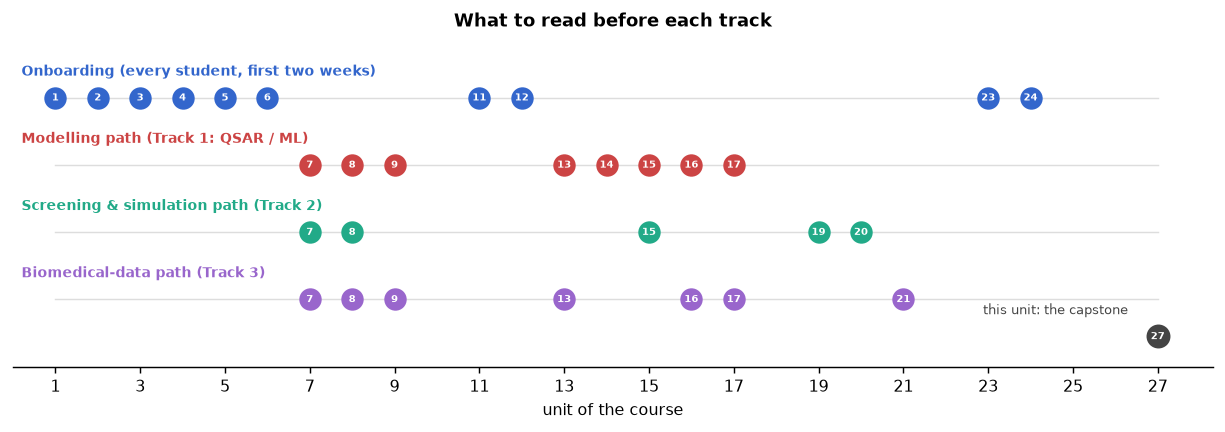

In [24]:
# Figure 11: the four reading paths of the course, by unit.
paths = {"Onboarding (every student, first two weeks)": [1, 2, 3, 4, 5, 6, 11, 12, 23, 24],
         "Modelling path (Track 1: QSAR / ML)": [7, 8, 9, 13, 14, 15, 16, 17],
         "Screening & simulation path (Track 2)": [7, 8, 15, 19, 20],
         "Biomedical-data path (Track 3)": [7, 8, 9, 13, 16, 17, 21]}
colours = ["#36c", "#c44", "#2a8", "#96c"]
fig, ax = plt.subplots(figsize=(9.5, 3.4))
for j, (name, units) in enumerate(paths.items()):
    yy = len(paths) - j
    ax.plot([1, 27], [yy, yy], color="#ddd", lw=0.8, zorder=0)
    ax.scatter(units, [yy] * len(units), s=130, color=colours[j], zorder=3)
    for u in units:
        ax.text(u, yy, str(u), ha="center", va="center", fontsize=5.6, color="white", fontweight="bold")
    ax.text(0.2, yy + 0.33, name, fontsize=7.5, color=colours[j], fontweight="bold")
ax.scatter([27], [0.45], s=150, color="#444")
ax.text(27, 0.45, "27", ha="center", va="center", fontsize=5.8, color="white", fontweight="bold")
ax.text(26.3, 0.78, "this unit: the capstone", fontsize=7, color="#444", ha="right")
ax.set_xlim(0, 28.3); ax.set_ylim(0, len(paths) + 0.9); ax.set_yticks([])
ax.set_xticks(range(1, 28, 2)); ax.set_xlabel("unit of the course")
ax.set_title("What to read before each track")
ax.spines["left"].set_visible(False)
fig.tight_layout()
print("units on each path:", {k: len(v) for k, v in paths.items()})

<p class="caption"><b>Figure 11.</b> The four reading paths. Everyone reads the ten onboarding units; the track adds five to eight more. No path contains all 27, intentionally: the extended units (10, 18, 21, 22, 25, 26) each belong to the track that needs them — unit 21 to the biomedical-data path, unit 22 to its optional extension — rather than to every reader. Unit 27 closes every path.</p>

Concretely, by project type:

- **Track 1 (QSAR / virtual screening).** <a href="../U6_Data_Quality/index.html">Unit 6</a> for curation and the noise floor, <a href="../U11_Supervised_Workflow/index.html">Unit 11</a> for the leakage-free pipeline, <a href="../U12_Validation/index.html">Unit 12</a> for splits and metrics, <a href="../U14_Ensembles_Tuning/index.html">Unit 14</a> for tuning under a budget, <a href="../U16_Interpretability/index.html">Unit 16</a> before interpreting a forest, <a href="../U17_Uncertainty_AD/index.html">Unit 17</a> to replace Section 4.8's similarity rule with conformal intervals, and <a href="../U19_Virtual_Screening/index.html">Unit 19</a> once the deliverable is a ranked list.
- **Track 2 (simulation analytics).** <a href="../U7_Estimation/index.html">Unit 7</a> for the bootstrap, <a href="../U8_Hypothesis_Testing/index.html">Unit 8</a> for effect sizes and paired tests, <a href="../U15_Clustering/index.html">Unit 15</a> for clustering and its stability, and above all <a href="../U20_MD_Analytics/index.html">Unit 20</a> for autocorrelation, block averaging and replica-level uncertainty; <a href="../U25_Scaling_HPC/index.html">Unit 25</a> if the trajectories must be produced.
- **Track 3 (biomedical data).** <a href="../U9_Linear_Models/index.html">Unit 9</a> for the linear model behind every differential analysis, <a href="../U13_Features_Dimensionality/index.html">Unit 13</a> for selection inside the folds, <a href="../U21_Omics/index.html">Unit 21</a> for differential expression and enrichment, <a href="../U22_Networks/index.html">Unit 22</a> if the interpretation becomes a network, <a href="../U17_Uncertainty_AD/index.html">Unit 17</a> for calibration.
- **Everyone, in the last two stages.** <a href="../U23_Communication/index.html">Unit 23</a> for figures and reporting standards, <a href="../U24_Software_Engineering/index.html">Unit 24</a> for the package, tests and CI, <a href="../U2_Reproducibility/index.html">Unit 2</a> for the DOI and the FAIR checklist, <a href="../U26_Apps_Deployment/index.html">Unit 26</a> if somebody who does not write code must use the result.

<div class="box bridge"><h4>Bridge — the three sister courses</h4>
<p>This course teaches the data science; the domain machinery lives next door. The bioinformatics course <a href="../../BGM324/01_Sequence_Alignment/index.html">BGM324</a> covers what produces your data — <a href="../../BGM324/01_Sequence_Alignment/index.html">sequence alignment</a>, <a href="../../BGM324/02_Protein_Structure_Prediction/index.html">structure prediction</a>, <a href="../../BGM324/03_Molecular_Docking/index.html">docking</a>, <a href="../../BGM324/04_Computer_Aided_Drug_Design/index.html">drug design</a> and <a href="../../BGM324/05_Molecular_Dynamics/index.html">molecular dynamics</a> — the generators behind Tracks 1 and 2. The artificial-intelligence course <a href="../../BGM411/Python/index.html">BGM411</a> treats the algorithms in more depth than Block D. The cheminformatics course closes the loop for Track 1: its <a href="../../Cheminformatics/U7_Data_Curation/index.html">curation</a>, <a href="../../Cheminformatics/U12_Classical_QSAR/index.html">classical QSAR</a> and <a href="../../Cheminformatics/U14_Validation/index.html">validation</a> units cover the same ground from the chemistry side, and its <a href="../../Cheminformatics/U19_Capstone/index.html">capstone</a> is a sibling of this one.</p></div>

## 9. Summary

A capstone is a claim, defended. What this unit adds to the techniques of the previous twenty-six is procedural, and it fits on one page:

- choose a track and write its specification — data, unit of prediction, validation, deliverable claim — first;
- write the analysis plan, including the result that would make you say the model does not work, and log every deviation;
- freeze and hash the data on day one; the exclusion log is the data card;
- choose the split from the claim, not from the score, and run the trivial baseline first;
- tune inside the training folds, spend the hold-out once, and put an interval on every metric and on every difference;
- state where the model may speak and withhold the predictions outside it;
- read every result against the noise floor, not against zero;
- ship a repository with pinned versions, tests in CI and a DOI, generating Methods and model card from the code;
- run the audit before anybody else does.

The miniature produced the numbers to remember. On the ROCK1 scaffold hold-out of 553 compounds, a tuned random forest on Morgan fingerprints reaches RMSE about 0.83 log units, 95 % bootstrap interval roughly [0.77, 0.88], against 1.12 for a mean predictor and a noise floor of 0.51. Tuning changed the error by about −0.014 log units with an interval straddling zero, so it did not demonstrably help; the random split returned about 0.73 and was reported as a contrast. Error rose to about 1.04 log units — no better than the mean — for the 49 hold-out compounds below 0.30 similarity to training, and none of 4,000 external library molecules passed that domain rule, although the model printed a confident-looking prediction for every one. The twenty compounds the model would have ordered contained 80 % actives against a base rate of 21 %, an enrichment of about 3.8-fold: a modest, honest, checkable result of the kind a thesis chapter is made of.

Three habits outlast the course: the interval, the plan and the hash. The field's best-practice literature says little more, at greater length — for molecular machine learning<sup class="c"><a href="#r15">[15]</a></sup><sup class="c"><a href="#r19">[19]</a></sup>, for biological machine learning<sup class="c"><a href="#r12">[12]</a></sup>, for clinical prediction<sup class="c"><a href="#r13">[13]</a></sup> and for simulation<sup class="c"><a href="#r30">[30]</a></sup>.

## 10. Self-assessment

<details><summary>1. Why must the split be written into the plan before any model is fitted?</summary>Because once both numbers exist, choosing between them is a decision informed by the result, and nothing in the report records that. The miniature's random split returned 0.73 and its scaffold split 0.83: both are correct answers to different questions, and the plan is what keeps the headline attached to the question the claim needs.</details>

<details><summary>2. Your tuned model beats the untuned one by 0.014 log units. What do you write?</summary>That the difference is smaller than the hold-out can resolve: the paired bootstrap interval, about [−0.034, +0.003], includes zero. "Tuning did not measurably improve the model" is the honest sentence.</details>

<details><summary>3. What is the unit of prediction in each track, and why does it matter more than any other line of the plan?</summary>One compound (Track 1), one replica (Track 2), one patient (Track 3). It fixes the grouping variable of the split and therefore whether the validation is honest: 500 correlated frames treated as 500 observations, or two samples from one patient split across train and test, invalidate every interval downstream.</details>

<details><summary>4. A referee asks why your prioritised list is so short. What is the defensible answer?</summary>That predictions outside the applicability domain were withheld. In Section 4.8 the rule removed all 4,000 library candidates, each below 0.35 similarity to any training compound — which says the library is unsuitable for this model, not that the model is useless.</details>

<details><summary>5. Why is the noise floor part of the result?</summary>Because a metric read against zero is meaningless. RMSE 0.83 against replicate noise of 0.51 is a model within a factor of two of the measurement; the same 0.83 on data with 0.05 noise would be poor. The floor also stops a reader expecting an improvement the data cannot support.</details>

<details><summary>6. Which rubric criteria does a beautifully engineered project with a random split lose, and how many points?</summary>Statistical rigour and interpretation, which together carry 50 % of the mark. In the scored example of Figure 10, submission B lost 25.0 of its 37 missing points in those two criteria while scoring well on code and communication.</details>

<details><summary>7. What belongs in the data card that is not in the exclusion log?</summary>The licence, the defects that survive curation (pooled assay types; compounds whose replicates span more than a log unit) and the intended use with its out-of-scope counterpart. The log says what was removed; the card says what the survivors may be used for.</details>

<details><summary>8. Your project changed direction in month four. Does that cost you marks?</summary>Not if it is in the deviation log with its date and reason. What the rubric penalises is a report written as though the final plan had been the original one.</details>

<details><summary>9. Why does the audit cell raise an error instead of printing a warning?</summary>Because a checklist that can be ignored will be. Making the notebook fail when a check fails converts the checklist into a control, which is the same reason the three repository tests run in continuous integration rather than on request.</details>

<details><summary>10. What would turn the miniature into a publishable Track 1 project?</summary>A larger model comparison under nested validation, per-compound conformal intervals instead of one global rule, a y-scrambling control, an external — ideally prospective — set, and a real purchasable library inside the domain. The arc, the plan, the provenance and the audit would not change, which is the point.</details>

<details><summary>11. Two students report AUC 0.91 and 0.88 on the same biomedical dataset. What do you need before deciding whose model is better?</summary>The split (grouped by patient or not), an interval on each estimate and on their difference, the prevalence, and whether either protocol was chosen after the fact. Without those the numbers are not comparable; with them they are often indistinguishable.</details>

<details><summary>12. What is the first thing you do on day one?</summary>Download the data once, hash it, write the manifest, create the repository with the plan file in it. Everything else depends on that state existing before any analysis can influence a decision.</details>

## Glossary

<dl class="gloss">
<dt>Analysis plan (pre-registration)</dt><dd>A short document fixing question, target, unit of prediction, split, metric, decision rule and planned figures before modelling begins.</dd>
<dt>Applicability domain</dt><dd>An explicit rule stating for which new inputs a model's predictions may be quoted; here, a minimum Tanimoto similarity to the nearest training compound.</dd>
<dt>Audit checklist</dt><dd>A claim-by-claim verification run before submission; its mechanically checkable items are executed by code.</dd>
<dt>Base rate</dt><dd>The fraction of positives in the pool a selection is drawn from; the denominator of any enrichment factor.</dd>
<dt>Bootstrap interval</dt><dd>A confidence interval obtained by resampling the evaluation set with replacement and recomputing the metric.</dd>
<dt>Censored measurement</dt><dd>A record establishing only a bound on the quantity (for example "&gt; 10 µM"); kept and flagged, never treated as an exact value.</dd>
<dt>Continuous integration (CI)</dt><dd>Automatic execution of a repository's tests on every push, so that breakage is detected without being looked for.</dd>
<dt>Data card</dt><dd>A one-page description of a dataset: source, version, hash, counts, exclusions, defects, licence and intended use.</dd>
<dt>Deviation log</dt><dd>A dated record of every departure from the analysis plan, with its justification.</dd>
<dt>Enrichment factor</dt><dd>Hit rate in a selected subset divided by the base rate of the pool it was selected from.</dd>
<dt>Hold-out</dt><dd>The portion of the data reserved for a single final evaluation, spent once.</dd>
<dt>Leakage</dt><dd>Any path by which information from the evaluation data reaches the model or the protocol before evaluation.</dd>
<dt>Manifest</dt><dd>A machine-readable file listing every raw input with its hash, size and counts.</dd>
<dt>Model card</dt><dd>A structured description of a model: intended use, out-of-scope use, training distribution, metrics with intervals, limitations.</dd>
<dt>Noise floor</dt><dd>The irreducible error set by the reproducibility of the measurement itself; the ceiling on any model's accuracy.</dd>
<dt>Prioritised list</dt><dd>The deliverable of a ligand-based project: ranked candidates with predicted values, intervals and in-domain flags.</dd>
<dt>Provenance</dt><dd>The documented origin of a dataset: source, query, version, date, licence and hash.</dd>
<dt>Replica</dt><dd>An independent repetition of a simulation; the unit of observation in simulation analytics.</dd>
<dt>Scaffold split</dt><dd>A group split by Bemis–Murcko scaffold, largest families to training, that simulates prediction for unseen chemotypes.</dd>
<dt>Unit of prediction</dt><dd>The entity one row of the final table represents — a compound, a replica, a patient — from which the grouping of every split follows.</dd>
<dt>Winner's curse</dt><dd>The upward bias of the best of several noisy estimates; the reason a model must not be selected on the data used to report it.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Heil BJ, Hoffman MM, Markowetz F, Lee SI, Greene CS, Hicks SC. Reproducibility standards for machine learning in the life sciences. <em>Nat Methods</em>. 2021;18(10):1132-1135. <a href="https://doi.org/10.1038/s41592-021-01256-7">doi:10.1038/s41592-021-01256-7</a></li>
<li id="r2">Wilson G, Bryan J, Cranston K, Kitzes J, Nederbragt L, Teal TK. Good enough practices in scientific computing. <em>PLoS Comput Biol</em>. 2017;13(6):e1005510. <a href="https://doi.org/10.1371/journal.pcbi.1005510">doi:10.1371/journal.pcbi.1005510</a></li>
<li id="r3">Sandve GK, Nekrutenko A, Taylor J, Hovig E. Ten simple rules for reproducible computational research. <em>PLoS Comput Biol</em>. 2013;9(10):e1003285. <a href="https://doi.org/10.1371/journal.pcbi.1003285">doi:10.1371/journal.pcbi.1003285</a></li>
<li id="r4">Rule A, Birmingham A, Zuniga C, et al. Ten simple rules for writing and sharing computational analyses in Jupyter Notebooks. <em>PLoS Comput Biol</em>. 2019;15(7):e1007007. <a href="https://doi.org/10.1371/journal.pcbi.1007007">doi:10.1371/journal.pcbi.1007007</a></li>
<li id="r5">Wilkinson MD, Dumontier M, Aalbersberg IJ, et al. The FAIR Guiding Principles for scientific data management and stewardship. <em>Sci Data</em>. 2016;3:160018. <a href="https://doi.org/10.1038/sdata.2016.18">doi:10.1038/sdata.2016.18</a></li>
<li id="r6">Stodden V, McNutt M, Bailey DH, et al. Enhancing reproducibility for computational methods. <em>Science</em>. 2016;354(6317):1240-1241. <a href="https://doi.org/10.1126/science.aah6168">doi:10.1126/science.aah6168</a></li>
<li id="r7">Baker M. 1,500 scientists lift the lid on reproducibility. <em>Nature</em>. 2016;533(7604):452-454. <a href="https://doi.org/10.1038/533452a">doi:10.1038/533452a</a></li>
<li id="r8">Kapoor S, Narayanan A. Leakage and the reproducibility crisis in machine-learning-based science. <em>Patterns</em>. 2023;4(9):100804. <a href="https://doi.org/10.1016/j.patter.2023.100804">doi:10.1016/j.patter.2023.100804</a></li>
<li id="r9">Nosek BA, Ebersole CR, DeHaven AC, Mellor DT. The preregistration revolution. <em>Proc Natl Acad Sci USA</em>. 2018;115(11):2600-2606. <a href="https://doi.org/10.1073/pnas.1708274114">doi:10.1073/pnas.1708274114</a></li>
<li id="r10">Simmons JP, Nelson LD, Simonsohn U. False-positive psychology: undisclosed flexibility in data collection and analysis allows presenting anything as significant. <em>Psychol Sci</em>. 2011;22(11):1359-1366. <a href="https://doi.org/10.1177/0956797611417632">doi:10.1177/0956797611417632</a></li>
<li id="r11">Boulesteix AL. Ten simple rules for reducing overoptimistic reporting in methodological computational research. <em>PLoS Comput Biol</em>. 2015;11(4):e1004191. <a href="https://doi.org/10.1371/journal.pcbi.1004191">doi:10.1371/journal.pcbi.1004191</a></li>
<li id="r12">Walsh I, Fishman D, Garcia-Gasulla D, et al. DOME: recommendations for supervised machine learning validation in biology. <em>Nat Methods</em>. 2021;18(10):1122-1127. <a href="https://doi.org/10.1038/s41592-021-01205-4">doi:10.1038/s41592-021-01205-4</a></li>
<li id="r13">Collins GS, Moons KGM, Dhiman P, et al. TRIPOD+AI statement: updated guidance for reporting clinical prediction models that use regression or machine learning methods. <em>BMJ</em>. 2024;385:e078378. <a href="https://doi.org/10.1136/bmj-2023-078378">doi:10.1136/bmj-2023-078378</a></li>
<li id="r14">Riley RD, Ensor J, Snell KIE, et al. Calculating the sample size required for developing a clinical prediction model. <em>BMJ</em>. 2020;368:m441. <a href="https://doi.org/10.1136/bmj.m441">doi:10.1136/bmj.m441</a></li>
<li id="r15">Tropsha A. Best practices for QSAR model development, validation, and exploitation. <em>Mol Inform</em>. 2010;29(6-7):476-488. <a href="https://doi.org/10.1002/minf.201000061">doi:10.1002/minf.201000061</a></li>
<li id="r16">OECD. <em>Guidance Document on the Validation of (Quantitative) Structure-Activity Relationship [(Q)SAR] Models</em>. OECD Series on Testing and Assessment No. 69. Paris: OECD Publishing; 2014. <a href="https://doi.org/10.1787/9789264085442-en">doi:10.1787/9789264085442-en</a></li>
<li id="r17">Sheridan RP. Time-split cross-validation as a method for estimating the goodness of prospective prediction. <em>J Chem Inf Model</em>. 2013;53(4):783-790. <a href="https://doi.org/10.1021/ci400084k">doi:10.1021/ci400084k</a></li>
<li id="r18">Wallach I, Heifets A. Most ligand-based classification benchmarks reward memorization rather than generalization. <em>J Chem Inf Model</em>. 2018;58(5):916-932. <a href="https://doi.org/10.1021/acs.jcim.7b00403">doi:10.1021/acs.jcim.7b00403</a></li>
<li id="r19">Bender A, Schneider N, Segler M, Walters WP, Engkvist O, Rodrigues T. Evaluation guidelines for machine learning tools in the chemical sciences. <em>Nat Rev Chem</em>. 2022;6(6):428-442. <a href="https://doi.org/10.1038/s41570-022-00391-9">doi:10.1038/s41570-022-00391-9</a></li>
<li id="r20">Artrith N, Butler KT, Coudert FX, et al. Best practices in machine learning for chemistry. <em>Nat Chem</em>. 2021;13(6):505-508. <a href="https://doi.org/10.1038/s41557-021-00716-z">doi:10.1038/s41557-021-00716-z</a></li>
<li id="r21">Bemis GW, Murcko MA. The properties of known drugs. 1. Molecular frameworks. <em>J Med Chem</em>. 1996;39(15):2887-2893. <a href="https://doi.org/10.1021/jm9602928">doi:10.1021/jm9602928</a></li>
<li id="r22">Rogers D, Hahn M. Extended-connectivity fingerprints. <em>J Chem Inf Model</em>. 2010;50(5):742-754. <a href="https://doi.org/10.1021/ci100050t">doi:10.1021/ci100050t</a></li>
<li id="r23">Breiman L. Random forests. <em>Mach Learn</em>. 2001;45(1):5-32. <a href="https://doi.org/10.1023/A:1010933404324">doi:10.1023/A:1010933404324</a></li>
<li id="r24">Efron B. Bootstrap methods: another look at the jackknife. <em>Ann Stat</em>. 1979;7(1):1-26. <a href="https://doi.org/10.1214/aos/1176344552">doi:10.1214/aos/1176344552</a></li>
<li id="r25">Sahigara F, Mansouri K, Ballabio D, Mauri A, Consonni V, Todeschini R. Comparison of different approaches to define the applicability domain of QSAR models. <em>Molecules</em>. 2012;17(5):4791-4810. <a href="https://doi.org/10.3390/molecules17054791">doi:10.3390/molecules17054791</a></li>
<li id="r26">Roy K, Kar S, Ambure P. On a simple approach for determining applicability domain of QSAR models. <em>Chemometr Intell Lab Syst</em>. 2015;145:22-29. <a href="https://doi.org/10.1016/j.chemolab.2015.04.013">doi:10.1016/j.chemolab.2015.04.013</a></li>
<li id="r27">Zdrazil B, Felix E, Hunter F, et al. The ChEMBL Database in 2023: a drug discovery platform spanning multiple bioactivity data types and time periods. <em>Nucleic Acids Res</em>. 2024;52(D1):D1180-D1192. <a href="https://doi.org/10.1093/nar/gkad1004">doi:10.1093/nar/gkad1004</a></li>
<li id="r28">Mitchell M, Wu S, Zaldivar A, et al. Model cards for model reporting. In: <em>Proceedings of the Conference on Fairness, Accountability, and Transparency (FAT* '19)</em>. ACM; 2019:220-229. <a href="https://doi.org/10.1145/3287560.3287596">doi:10.1145/3287560.3287596</a></li>
<li id="r29">Gebru T, Morgenstern J, Vecchione B, et al. Datasheets for datasets. <em>Commun ACM</em>. 2021;64(12):86-92. <a href="https://doi.org/10.1145/3458723">doi:10.1145/3458723</a></li>
<li id="r30">Grossfield A, Patrone PN, Roe DR, Schultz AJ, Siderius DW, Zuckerman DM. Best practices for quantification of uncertainty and sampling quality in molecular simulations [Article v1.0]. <em>Living J Comput Mol Sci</em>. 2019;1(1):5067. <a href="https://doi.org/10.33011/livecoms.1.1.5067">doi:10.33011/livecoms.1.1.5067</a></li>
<li id="r31">Love MI, Huber W, Anders S. Moderated estimation of fold change and dispersion for RNA-seq data with DESeq2. <em>Genome Biol</em>. 2014;15(12):550. <a href="https://doi.org/10.1186/s13059-014-0550-8">doi:10.1186/s13059-014-0550-8</a></li>
<li id="r32">Subramanian A, Tamayo P, Mootha VK, et al. Gene set enrichment analysis: a knowledge-based approach for interpreting genome-wide expression profiles. <em>Proc Natl Acad Sci USA</em>. 2005;102(43):15545-15550. <a href="https://doi.org/10.1073/pnas.0506580102">doi:10.1073/pnas.0506580102</a></li>
<li id="r33">Benjamini Y, Hochberg Y. Controlling the false discovery rate: a practical and powerful approach to multiple testing. <em>J R Stat Soc Series B</em>. 1995;57(1):289-300. <a href="https://doi.org/10.1111/j.2517-6161.1995.tb02031.x">doi:10.1111/j.2517-6161.1995.tb02031.x</a></li>
<li id="r34">Taschuk M, Wilson G. Ten simple rules for making research software more robust. <em>PLoS Comput Biol</em>. 2017;13(4):e1005412. <a href="https://doi.org/10.1371/journal.pcbi.1005412">doi:10.1371/journal.pcbi.1005412</a></li>
<li id="r35">Grüning B, Chilton J, Köster J, et al. Practical computational reproducibility in the life sciences. <em>Cell Syst</em>. 2018;6(6):631-635. <a href="https://doi.org/10.1016/j.cels.2018.03.014">doi:10.1016/j.cels.2018.03.014</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>The Turing Way Community. <em>The Turing Way: A Handbook for Reproducible, Ethical and Collaborative Research</em> (online, continuously updated). — The reference work behind most of Sections 1, 4.1 and 4.11; read the "Guide for Reproducible Research" before stage S1.</li>
<li>James G, Witten D, Hastie T, Tibshirani R, Taylor J. <em>An Introduction to Statistical Learning with Applications in Python</em>. Springer; 2023 (free PDF). — The statistical background of Tracks 1 and 3 at the level of this course.</li>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009 (free PDF). — Chapter 7 for everything the validation sections assume.</li>
<li>Steyerberg EW. <em>Clinical Prediction Models</em>. 2nd ed. Springer; 2019. — The Track 3 counterpart of the validation and calibration discipline taught here.</li>
<li>VanderPlas J. <em>Python Data Science Handbook</em>. 2nd ed. O'Reilly; 2022 (free online). — The toolbox reference for the whole course.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>Zenodo and the GitHub–Zenodo integration, for minting the DOI of an archived release: <a href="https://zenodo.org/">zenodo.org</a>.</li>
<li>scikit-learn user guide, "Cross-validation" and "Metrics and scoring": <a href="https://scikit-learn.org/stable/user_guide.html">scikit-learn.org/stable/user_guide.html</a>.</li>
<li>TRIPOD+AI reporting checklist for prediction-model studies: <a href="https://www.tripod-statement.org/">tripod-statement.org</a>.</li>
<li>TeachOpenCADD talktorials, for Track 1 worked pipelines: <a href="https://projects.volkamerlab.org/teachopencadd/">projects.volkamerlab.org/teachopencadd</a>.</li>
<li>Practical Cheminformatics (P. Walters), for scaffold splits, benchmarks and model comparison: <a href="https://patwalters.github.io/practicalcheminformatics/">patwalters.github.io/practicalcheminformatics</a>.</li>
<li>LiveCoMS best-practice articles, for Track 2 simulation analysis: <a href="https://livecomsjournal.org/">livecomsjournal.org</a>.</li>
</ul>